# LABELING & FEATURE ENGINEERING

<h3>Cell 0 Import & Setup</h3>
<p>
Di tahap awal, kami mempersiapkan environment (numpy/pandas/matplotlib), set display option agar inspeksi kolom lebih nyaman, dan membaca dataset mentah <code>SPARC_dataset.csv</code> dari path yang sama dengan notebook (menggunakan <code>os.getcwd()</code>).
</p>
<p>
Hasilnya dataset berhasil terbaca dengan ukuran <b>319,978 baris</b> dan <b>28 kolom</b>. Kami juga melihat warning <i>DtypeWarning</i> yang mengindikasikan beberapa kolom bertipe campuran (mixed types). Ini wajar pada data real-world dan jadi sinyal bahwa kami harus melakukan cleaning/standardisasi tipe data pada tahap berikutnya.
</p>

In [1]:
import os
import re
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

csv_path = os.path.join(os.getcwd(), "SPARC_dataset.csv")
print("CSV path:", csv_path)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

CSV path: c:\Patrick\coding\save later\sparc\SPARC_dataset.csv
Shape: (319978, 28)


C:\Users\timot\AppData\Local\Temp\ipykernel_26180\1543217413.py:17: DtypeWarning: Columns (3,19,23,24,26) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


,Customer ID,Kelurahan,Kecamatan,Kode POS,Cash/Credit,Kode Dealer,Finance Company,Tenor,Gender,Tgl Lahir,Agama,Pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,OTR,tahun rakit,DLR group,tgl cetak,tgl mohon,Kode Kota-Provinsi
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03 0:00:00,1,2e,27.0,Rp 21.000.000,Rp 8.600.000,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02-01-2019,6471-6400
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27 0:00:00,1,2b,28.0,87800000,20600000,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02012019,6471-6400
2,CUST-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-01-04 0:00:00,1,4b,37.0,Rp 0,Rp 0,MH,Balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02012019,6471-6400
3,CUST-164422,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1997-06-26 0:00:00,1,11,22.0,0,0,MH,Balikpapan,SCOOTY SERIES,krg 1 jt,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02012019,6471-6400
4,CUST-155472,Baru Ulu,Balikpapan Barat,76133,2.0,11160.0,1,2,1,1996-07-12 0:00:00,1,2e,23.0,21000000,12200000,MH,Balikpapan,SCOOTY SERIES,2 - 3 jt,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,02-01-2019,6471-6400


<h3>Cell 1 - Quick Check (Info, Missing, Duplicates)</h3>
<p>
Di cell ini kami melakukan sanity check: melihat tipe data, persentase missing value, dan mengecek duplikasi baris persis sama.
</p>
<ul>
  <li>
    <b>Temuan missing value besar:</b> kolom <code>dlr group</code> missing sekitar <b>80.69%</b>.
    Ini artinya kolom tersebut bisa dipakai, tapi perlu strategi: treat sebagai kategori dengan banyak missing atau dipertimbangkan untuk tidak jadi fitur utama.
  </li>
  <li>
    <b>Duplikasi baris exact:</b> ditemukan <b>2,341</b> baris duplikat persis.
    Ini menjelaskan kenapa metrik “repeat per customer” bisa kelihatan janggal kalau hanya menghitung jumlah baris.
  </li>
  <li>
    <b>Issue kecil:</b> di awal cell kami sempat mengecek <code>customer id</code>, tetapi nama kolom di file masih “Customer ID” (case + spasi). Ini diselesaikan di cell berikutnya dengan standarisasi nama kolom.
  </li>
</ul>

In [2]:
# 1) Quick Check: info, missing, duplicates
display(df.info())

missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing_df = pd.DataFrame({"missing_%": missing, "missing_count": df.isna().sum()})
display(missing_df.head(20))

# cek duplikasi row 
dup_rows = df.duplicated().sum()
print("Duplicate rows (exact):", dup_rows)

# cek duplikasi customer id
if "customer id" in df.columns:
    cust_counts = df["customer id"].value_counts(dropna=False)
    print("Unique customer id:", cust_counts.shape[0])
    print("Customer repeat rate (customer muncul >1x):", (cust_counts.gt(1).mean()*100).round(2), "%")
else:
    print("Kolom 'customer id' tidak ditemukan. Cek nama kolom:", df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319978 entries, 0 to 319977
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Customer ID         319964 non-null  object 
 1   Kelurahan           319962 non-null  object 
 2   Kecamatan           319963 non-null  object 
 3   Kode POS            319963 non-null  object 
 4   Cash/Credit         319963 non-null  float64
 5   Kode Dealer         319963 non-null  float64
 6   Finance Company     319889 non-null  object 
 7   Tenor               319942 non-null  object 
 8   Gender              319962 non-null  object 
 9   Tgl Lahir           319963 non-null  object 
 10  Agama               319963 non-null  object 
 11  Pekerjaan           319963 non-null  object 
 12  umur                319963 non-null  float64
 13  dp aktual           319234 non-null  object 
 14  cicilan             319276 non-null  object 
 15  warna               319963 non-nul

None

,missing_%,missing_count
9 segment,0.004688,15
Agama,0.004688,15
Cash/Credit,0.004688,15
Customer ID,0.004375,14
DLR group,80.687110,258181
Finance Company,0.027814,89
Gender,0.005000,16
Kecamatan,0.004688,15
Kelurahan,0.005000,16
Kode Dealer,0.004688,15


Duplicate rows (exact): 2341
Kolom 'customer id' tidak ditemukan. Cek nama kolom: ['Customer ID', 'Kelurahan', 'Kecamatan', 'Kode POS', 'Cash/Credit', 'Kode Dealer', 'Finance Company', 'Tenor', 'Gender', 'Tgl Lahir', 'Agama', 'Pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'OTR', 'tahun rakit', 'DLR group', 'tgl cetak', 'tgl mohon', 'Kode Kota-Provinsi']


<h3>Cell 2 - Standarisasi Nama Kolom</h3>
<p>
Agar konsisten dan menghindari error karena perbedaan kapital/spasi, kami ubah semua nama kolom menjadi lowercase dan strip whitespace.
</p>
<p>
Hasilnya, kolom seperti <code>Customer ID</code> menjadi <code>customer id</code>, dan ini membuat seluruh pipeline (labeling, EDA, grouping) lebih stabil dan tidak mudah gagal karena mismatch nama kolom.
</p>

In [3]:
# 2) Standarisasi nama kolom
df.columns = [c.strip().lower() for c in df.columns]
print(df.columns.tolist())
df.head(2)

['customer id', 'kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'tgl lahir', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'tgl cetak', 'tgl mohon', 'kode kota-provinsi']


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03 0:00:00,1,2e,27.0,Rp 21.000.000,Rp 8.600.000,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02-01-2019,6471-6400
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27 0:00:00,1,2b,28.0,87800000,20600000,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,02012019,6471-6400


<h3>Cell 3 - Cleaning Currency (dp aktual, cicilan)</h3>
<p>
Di data mentah, kolom seperti <code>dp aktual</code> dan <code>cicilan</code> berbentuk teks (mis. mengandung "Rp", titik pemisah ribuan, dsb). 
Kalau langsung dipakai untuk statistik/modeling, akan menyebabkan kolom dianggap <code>object</code> dan operasi numerik seperti mean/median bisa error.
</p>
<p>
kami bikin helper <code>currency_to_num()</code> yang mengambil digit saja, lalu convert menjadi float.
Hasilnya kedua kolom berhasil menjadi numerik dan bisa dihitung deskriptif statistiknya.
</p>
<p>
Catatan: karena kami hanya mengambil digit, nilai seperti "0" atau format aneh tetap akan masuk sebagai angka. Ini OK untuk baseline, tetapi bisa ditambah validasi outlier di tahap modeling.
</p>

In [4]:
# 3) Helper: bersihin currency jadi angka
def currency_to_num(x):
    """
    Contoh input:
    - "Rp 21.000.000" -> 21000000
    - "21.000.000" -> 21000000
    - 21000000 -> 21000000
    - "-" / "" / NaN -> NaN
    """
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s == "" or s.lower() in ["nan", "none", "-", "null"]:
        return np.nan
    # ambil digit saja
    digits = re.sub(r"[^\d]", "", s)
    if digits == "":
        return np.nan
    try:
        return float(digits)
    except:
        return np.nan

currency_cols = []
for c in ["dp aktual", "cicilan"]:
    if c in df.columns:
        currency_cols.append(c)

print("Currency columns found:", currency_cols)

for c in currency_cols:
    df[c] = df[c].map(currency_to_num)

df[currency_cols].describe().T if currency_cols else "Tidak ada kolom currency yang cocok."

Currency columns found: ['dp aktual', 'cicilan']


,count,mean,std,min,25%,50%,75%,max
dp aktual,319234.0,1.589836e+07,6.794624e+07,0.0,0.0,2100000.0,24000000.0,3.000000e+10
cicilan,319276.0,8.039088e+06,3.189562e+08,0.0,0.0,1425000.0,12700000.0,8.575233e+10


<h3>Cell 4 - Parser Tanggal (Fixed) + QC Parsing</h3>
<p>
Ini bagian krusial: dataset tidak menyediakan label, jadi label harus dibuat berdasarkan urutan waktu. Maka parsing <code>tgl mohon</code> harus benar.
</p>
<p>
Awalnya parsing sempat gagal karena format dominan ternyata <b>8 digit</b> seperti <code>19012019</code> (ddmmyyyy). Kalau diparse asal, bisa dibaca sebagai tahun 1901 atau dianggap format lain.
</p>
<p>
Solusinya: di helper <code>parse_mixed_date()</code>, untuk string 8 digit kami paksa mencoba <b>ddmmyyyy dulu</b> (<code>%d%m%Y</code>), baru kalau gagal mencoba <code>%Y%m%d</code>.
</p>
<p>
QC membuktikan perbaikan berhasil: dari data raw, gagal parse yang “raw ada isi tapi NaT” tinggal <b>1 baris</b> saja, yaitu nilai <code>319977</code> yang jelas bukan tanggal.
</p>
<ul>
  <li>Parsed <code>tgl mohon</code>: <b>69.48%</b> non-null datetime</li>
  <li>Parsed <code>tgl lahir</code>: <b>100%</b> non-null datetime</li>
  <li>Parsed <code>tgl cetak</code>: sangat kecil (sekitar <b>0.06%</b>) → kolom ini jarang terisi</li>
</ul>

In [5]:
# 4) Helper: parsing tanggal
def parse_mixed_date(x):
    if pd.isna(x):
        return pd.NaT

    if isinstance(x, (pd.Timestamp, np.datetime64)):
        return pd.to_datetime(x, errors="coerce")

    s = str(x).strip()
    if s == "" or s.lower() in ["nan", "none", "null", "-"]:
        return pd.NaT

    digits = re.sub(r"[^\d]", "", s)

    if len(digits) == 8 and digits.isdigit():
        dt1 = pd.to_datetime(digits, format="%d%m%Y", errors="coerce")
        if not pd.isna(dt1):
            return dt1
        dt2 = pd.to_datetime(digits, format="%Y%m%d", errors="coerce")
        return dt2

    return pd.to_datetime(s, errors="coerce", dayfirst=True)


date_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in df.columns]
print("Date columns found:", date_cols)

for c in date_cols:
    df[c] = df[c].map(parse_mixed_date)

for c in date_cols:
    ok = df[c].notna().mean() * 100
    print(f"Parsed {c}: {ok:.2f}% non-null datetime")


csv_path = os.path.join(os.getcwd(), "SPARC_dataset.csv")
raw = pd.read_csv(csv_path, usecols=["tgl mohon"], dtype={"tgl mohon": "string"})
parsed_raw = raw["tgl mohon"].map(parse_mixed_date)

bad_mask = raw["tgl mohon"].notna() & parsed_raw.isna()
bad = raw.loc[bad_mask, "tgl mohon"].astype(str)

print("\n--- QC raw tgl mohon ---")
print("Total rows (raw):", raw.shape[0])
print("Raw tgl mohon null %:", (raw["tgl mohon"].isna().mean() * 100))
print("Total gagal parse (raw ada isi tapi NaT):", bad.shape[0])
print("Persentase gagal parse:", round((bad.shape[0] / raw.shape[0] * 100), 4), "%")

if bad.shape[0] > 0:
    print("\nContoh nilai tgl mohon yang gagal parse (20 teratas):")
    display(bad.head(20).to_frame(name="tgl_mohon_raw"))

    print("\nDistribusi panjang string (top 10):")
    display(bad.str.len().value_counts().head(10).to_frame("count"))

    print("\nTop 20 nilai mentah yang paling sering muncul:")
    display(bad.value_counts().head(20).to_frame("count"))

Date columns found: ['tgl mohon', 'tgl cetak', 'tgl lahir']


C:\Users\timot\AppData\Local\Temp\ipykernel_26180\1495879426.py:22: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  return pd.to_datetime(s, errors="coerce", dayfirst=True)


Parsed tgl mohon: 69.48% non-null datetime
Parsed tgl cetak: 0.06% non-null datetime
Parsed tgl lahir: 100.00% non-null datetime

--- QC raw tgl mohon ---
Total rows (raw): 319978
Raw tgl mohon null %: 0.004375300801930133
Total gagal parse (raw ada isi tapi NaT): 1
Persentase gagal parse: 0.0003 %

Contoh nilai tgl mohon yang gagal parse (20 teratas):


,tgl_mohon_raw
319977,319977



Distribusi panjang string (top 10):


,count
tgl mohon,
6,1



Top 20 nilai mentah yang paling sering muncul:


,count
tgl mohon,
319977,1


<h3>Cell 5 - Labeling Target</h3>
<p>
Tujuan label: <b>0</b> jika customer tidak ada transaksi berikutnya, <b>1</b> jika ada transaksi setelah transaksi ini.
</p>
<p>
Masalah versi awal: kalau customer punya banyak baris di <b>tanggal yang sama</b> (duplicate administratif), metode “urutan transaksi” bisa memberi label <code>1</code> padahal tidak ada transaksi di masa depan (hanya duplikasi same-day).
</p>
<p>
Perbaikan: kami pakai definisi <b>strict later date</b>:
<code>label = 1 jika max(tgl_mohon_customer) &gt; tgl_mohon_row</code>.
Dengan ini, baris yang berada di tanggal maksimum customer akan selalu bernilai 0, meski duplicate same-day banyak.
</p>
<p>
Hasil labeling:
</p>
<ul>
  <li>Total rows tetap: <b>319,978</b></li>
  <li>Rows valid untuk label (customer id & tgl mohon ada): <b>222,314</b></li>
  <li>Distribusi label: <b>0 = 194,516</b>, <b>1 = 27,798</b>, <b>NaN = 97,664</b></li>
</ul>
<p>
NaN bukan error: itu karena <code>tgl mohon</code> kosong sehingga tidak bisa menentukan urutan waktu.
</p>
<p>
Kami juga dokumentasikan duplikasi key <code>(customer id + tgl mohon)</code> sebanyak <b>12,824</b>, untuk menjelaskan kenapa pendekatan strict later date diperlukan.
</p>

In [6]:
# 5) Labeling target
import numpy as np
import pandas as pd

print("Rows in df (should match CSV lines):", df.shape[0])

required_cols = ["customer id", "tgl mohon"]
missing_required = [c for c in required_cols if c not in df.columns]
print("Missing required cols:", missing_required)

df["label_repeat_next"] = np.nan

if len(missing_required) == 0:
    mask_valid = df["customer id"].notna() & df["tgl mohon"].notna()
    print("Rows with customer id & valid tgl mohon:", int(mask_valid.sum()))

    tmp = df.loc[mask_valid, ["customer id", "tgl mohon"]].copy()

    # hitung max date per customer
    tmp["max_tgl_mohon_customer"] = tmp.groupby("customer id")["tgl mohon"].transform("max")

    tmp["label_repeat_next"] = (tmp["max_tgl_mohon_customer"] > tmp["tgl mohon"]).astype(int)

    df.loc[tmp.index, "label_repeat_next"] = tmp["label_repeat_next"].values

    df.loc[tmp.index, "max_tgl_mohon_customer"] = tmp["max_tgl_mohon_customer"].astype("datetime64[ns]")

    print("\n--- Label distribution (label_repeat_next) ---")
    print(df["label_repeat_next"].value_counts(dropna=False))
    print("Sum of counts:", int(df["label_repeat_next"].value_counts(dropna=False).sum()), "| df rows:", df.shape[0])

    dup_key = df.duplicated(subset=["customer id", "tgl mohon"]).sum()
    print("Duplicate (customer id + tgl mohon) rows in df:", int(dup_key))

else:
    print("Tidak bisa buat label time-aware karena kolom wajib tidak lengkap.")

Rows in df (should match CSV lines): 319978
Missing required cols: []
Rows with customer id & valid tgl mohon: 222314

--- Label distribution (label_repeat_next) ---
label_repeat_next
0.0    194516
NaN     97664
1.0     27798
Name: count, dtype: int64
Sum of counts: 319978 | df rows: 319978
Duplicate (customer id + tgl mohon) rows in df: 12824


<h3>Cell 5B - QC Labeling (Validasi dengan Tanggal Unik)</h3>
<p>
Di sini kami memastikan bahwa label <code>1</code> hanya muncul pada customer yang benar-benar memiliki transaksi pada lebih dari satu tanggal.
</p>
<p>
Kami hitung <code>n_unique_dates</code> per customer, lalu cek “suspect cases”:
customer yang punya <code>label=1</code> tetapi hanya memiliki <code>1</code> tanggal unik.
</p>
<p>
Hasilnya sangat bagus: <b>suspect = 0</b>. Artinya labeling strict later date sudah konsisten dengan definisi repeat berdasarkan waktu, dan tidak tertipu oleh duplikasi same-day.
</p>
<p>
Tambahan insight: customer valid-date yang punya &gt;1 tanggal transaksi adalah <b>19,100</b> (~<b>9.92%</b>).
</p>

In [7]:
# 5B) QC Labeling: cek repeat per customer berbasis tanggal unik
import pandas as pd

mask_valid = df["customer id"].notna() & df["tgl mohon"].notna()
tmp = df.loc[mask_valid, ["customer id", "tgl mohon", "label_repeat_next"]].copy()

# jumlah tanggal unik per customer
tmp["n_unique_dates"] = tmp.groupby("customer id")["tgl mohon"].transform("nunique")

cust_unique_dates = tmp.groupby("customer id")["tgl mohon"].nunique()
print("Customer unik (valid date):", cust_unique_dates.shape[0])
print("Customer dengan >1 tanggal transaksi:", int((cust_unique_dates > 1).sum()),
      "(", round((cust_unique_dates > 1).mean() * 100, 2), "% )")

check = tmp.groupby("customer id").agg(
    any_label1=("label_repeat_next", "max"),
    n_unique_dates=("tgl mohon", "nunique")
).reset_index()

suspect = check[(check["any_label1"] == 1) & (check["n_unique_dates"] <= 1)]
print("Customer yang punya label=1 tapi cuma 1 tanggal unik (harusnya 0):", suspect.shape[0])
display(suspect.head(10))

Customer unik (valid date): 192510
Customer dengan >1 tanggal transaksi: 19100 ( 9.92 % )
Customer yang punya label=1 tapi cuma 1 tanggal unik (harusnya 0): 0


,customer id,any_label1,n_unique_dates


<h3>Cell 6 - EDA Insight Dasar</h3>
<p>
Setelah label terbentuk, kami hitung repeat-next rate pada data yang berlabel.
Hasilnya <b>12.50%</b> transaksi memiliki transaksi berikutnya (label=1), dan kami visualisasikan distribusi label untuk melihat imbalance.
</p>
<p>
Kami juga membuat fungsi <code>repeat_rate_by()</code> untuk melihat repeat rate berdasarkan fitur kategori seperti cash/credit, tenor, segment, dealer, wilayah, dll.
Ini membantu memilih fitur yang potensial untuk modeling dan juga memberi insight awal untuk laporan.
</p>
<p>
Catatan: untuk kategori dengan n sangat kecil, repeat rate bisa misleading (misalnya wilayah dengan n=1 → 100%).
Di notebook EDA lanjutan, kami tambahkan filter minimum sample agar lebih stabil.
</p>

Repeat-next rate (per transaksi, pada data berlabel): 12.50%


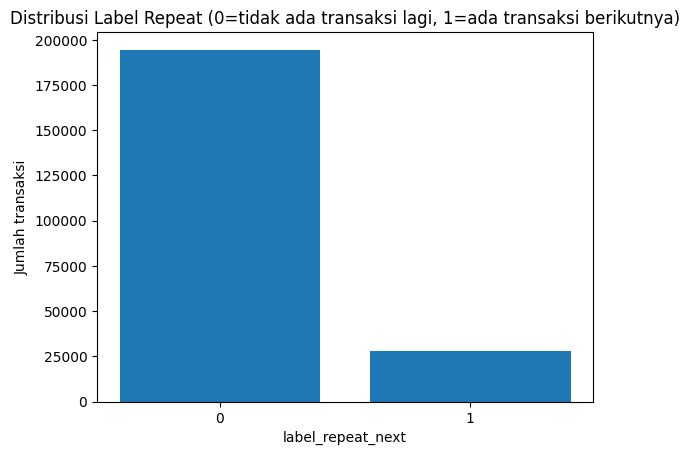

In [8]:
# 6) EDA Insight dasar terkait repeat
if "label_repeat_next" in df.columns:
    labeled = df[df["label_repeat_next"].notna()].copy()
    repeat_rate = labeled["label_repeat_next"].mean() * 100
    print(f"Repeat-next rate (per transaksi, pada data berlabel): {repeat_rate:.2f}%")

    # Plot distribusi label
    vc = labeled["label_repeat_next"].value_counts().sort_index()
    plt.figure()
    plt.bar(vc.index.astype(int).astype(str), vc.values)
    plt.title("Distribusi Label Repeat (0=tidak ada transaksi lagi, 1=ada transaksi berikutnya)")
    plt.xlabel("label_repeat_next")
    plt.ylabel("Jumlah transaksi")
    plt.show()

In [9]:
# 6.2 Insight awal: repeat rate per metode bayar (cash/credit), tenor, segment, dealer wilayah
def repeat_rate_by(col):
    if "label_repeat_next" not in df.columns:
        return None
    tmp = df[df["label_repeat_next"].notna()].copy()
    if col not in tmp.columns:
        print("Kolom tidak ada:", col)
        return None

    tab = (tmp.groupby(col)["label_repeat_next"]
             .agg(["count", "mean"])
             .rename(columns={"count": "n", "mean": "repeat_rate"}))
    tab["repeat_rate_%"] = tab["repeat_rate"] * 100
    tab = tab.sort_values("repeat_rate_%", ascending=False)
    return tab

for col in ["cash/credit", "tenor", "9 segment", "dealer", "wilayah", "dlr group", "finance company"]:
    if col in df.columns:
        print("\n=== Repeat rate by:", col, "===")
        tab = repeat_rate_by(col)
        display(tab.head(15))


=== Repeat rate by: cash/credit ===


,n,repeat_rate,repeat_rate_%
cash/credit,,,
1.0,97372,0.128312,12.831204
2.0,124942,0.122489,12.248883



=== Repeat rate by: tenor ===


,n,repeat_rate,repeat_rate_%
tenor,,,
4,120,0.291667,29.166667
1,26664,0.161679,16.167867
N,97341,0.128137,12.813717
2,75523,0.118679,11.867908
3,22647,0.088974,8.897426
5,3,0.000000,0.000000
6,3,0.000000,0.000000



=== Repeat rate by: 9 segment ===


,n,repeat_rate,repeat_rate_%
9 segment,,,
SPORT LOW,6794,0.463939,46.393877
CUB LOW,6395,0.260360,26.035966
SPORT HIGH,187,0.187166,18.716578
SPORT MID,9129,0.170884,17.088400
CUB HIGH,1815,0.169146,16.914601
CUB MID,4512,0.165559,16.555851
AT LOW,79011,0.110314,11.031375
EV AT HIGH,93,0.107527,10.752688
AT MID,76160,0.103020,10.301996


... (4 outputs left out)


=== Repeat rate by: dlr group ===


,n,repeat_rate,repeat_rate_%
dlr group,,,
SJX,3202,0.195503,19.550281
DAC,2523,0.174396,17.439556
MMX,2134,0.171978,17.197751
SX,22268,0.169705,16.970541
DMX,566,0.169611,16.961131
8X,812,0.168719,16.871921
TDX,3886,0.164951,16.495111
HV,5646,0.164010,16.400992
NSX,1324,0.157855,15.785498



=== Repeat rate by: finance company ===


,n,repeat_rate,repeat_rate_%
finance company,,,
11,4988,0.156375,15.637530
2,10118,0.145977,14.597747
13,1125,0.131556,13.155556
3,2458,0.130594,13.059398
N,97309,0.128272,12.827179
1,92857,0.122619,12.261865
9,1288,0.118012,11.801242
4,6457,0.091683,9.168344
36,734,0.081744,8.174387


<h3>Cell 6.3 - Insight Numerik vs Label</h3>
<p>
Kami bandingkan statistik numerik (dp aktual, cicilan, OTR, umur, tahun rakit) untuk label 0 vs 1.
Tujuan: melihat apakah ada kecenderungan nilai yang berbeda pada customer yang repeat.
</p>
<p>
Hasil awal menunjukkan beberapa perbedaan median yang cukup jelas (misalnya dp aktual dan cicilan median lebih tinggi pada label=1),
dan boxplot membantu memvisualisasikan perbedaan distribusi.
</p>
<p>
Catatan penting: ada outlier besar (max sangat tinggi) yang bisa mengganggu mean,
jadi median/quantile lebih dipercaya untuk insight.
Nanti di preprocessing modeling, outlier handling bisa dipertimbangkan (clipping / log transform).
</p>

Numeric cols found: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit']


label_repeat_next           0.0           1.0
dp aktual count    1.941670e+05  2.772200e+04
          mean     1.584712e+07  2.124157e+07
          std      4.965637e+07  1.826970e+08
          min      0.000000e+00  0.000000e+00
          25%      0.000000e+00  0.000000e+00
          50%      2.100000e+06  6.000000e+06
          75%      2.400000e+07  3.000000e+07
          max      1.810870e+10  3.000000e+10
cicilan   count    1.942040e+05  2.772700e+04
          mean     8.140135e+06  1.008680e+07
          std      3.512178e+08  1.832714e+08
          min      0.000000e+00  0.000000e+00
          25%      0.000000e+00  0.000000e+00
          50%      1.435000e+06  2.450000e+06
          75%      1.250000e+07  1.400000e+07
          max      8.575233e+10  2.300001e+10
otr       count    1.945140e+05  2.779600e+04
          mean     5.866062e+07  5.151368e+07
          std      8.406487e+07  7.741706e+07
          min      0.000000e+00  1.331000e+07
          25%      2.106000e+07  1.994000e+07
          50%      2.316000e+07  2.207000e+07
          75%      3.161000e+07  2.817000e+07
          max      9.301000e+08  8.280000e+08
umur      count    1.945160e+05  2.779800e+04
          mean     8.484994e+01  7.824365e+01
          std      1.250965e+02  1.179984e+02
          min      0.000000e+00  0.000000e+00
          25%      2.700000e+01  2.900000e+01
          50%      3.800000e+01  3.800000e+01
          75%      5.100000e+01  4.900000e+01
          max      1.230000e+03  1.120000e+03

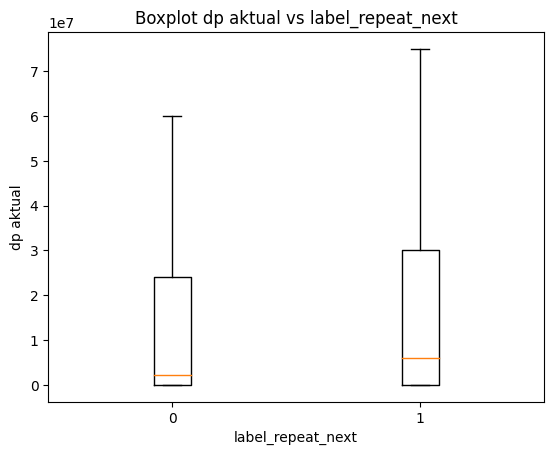

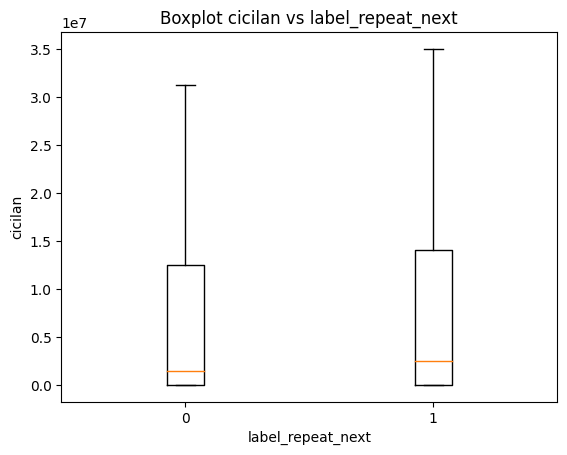

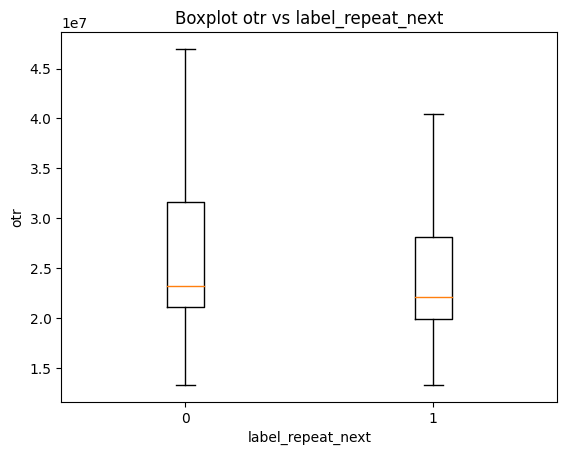

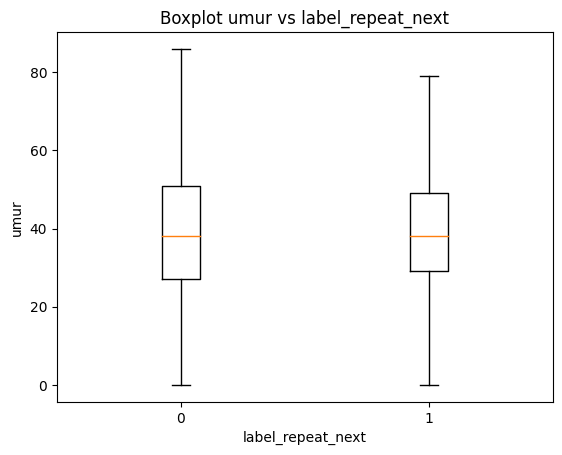

In [10]:
# 6.3 Insight numerik: hubungan dp/cicilan/OTR dengan repeat
num_cols = [c for c in ["dp aktual", "cicilan", "otr", "umur", "tahun rakit"] if c in df.columns]
print("Numeric cols found:", num_cols)

if "label_repeat_next" in df.columns and len(num_cols) > 0:
    tmp = df[df["label_repeat_next"].notna()].copy()

    summary = tmp.groupby("label_repeat_next")[num_cols].describe().T
    display(summary)

    for c in ["dp aktual", "cicilan", "otr", "umur"]:
        if c in tmp.columns:
            plt.figure()
            data0 = tmp.loc[tmp["label_repeat_next"] == 0, c].dropna()
            data1 = tmp.loc[tmp["label_repeat_next"] == 1, c].dropna()
            plt.boxplot([data0, data1], labels=["0", "1"], showfliers=False)
            plt.title(f"Boxplot {c} vs label_repeat_next")
            plt.xlabel("label_repeat_next")
            plt.ylabel(c)
            plt.show()

<h3>Cell 6.4 - Cek Potensi Data Leakage</h3>
<p>
Karena label dibuat dari informasi masa depan (transaksi setelah tanggal tertentu),
kami harus memastikan tidak ada fitur yang “membocorkan masa depan”.
</p>
<p>
Di pipeline kami, kolom helper seperti <code>tx_order</code> atau <code>tx_count_customer</code> tidak digunakan sebagai fitur.
Output menunjukkan daftar helper leakage kosong, jadi aman untuk lanjut.
</p>

In [11]:
# 6.4 Cek data leakage 
leak_cols = [c for c in ["tx_order", "tx_count_customer", "tgl_mohon_valid"] if c in df.columns]
print("Kolom helper (jangan dipakai untuk training kecuali jelas tersedia saat prediksi):", leak_cols)

Kolom helper (jangan dipakai untuk training kecuali jelas tersedia saat prediksi): []


<h3>PREP Cell A - Preprocessing untuk Modeling (Clean Types + Normalisasi Kategori)</h3>
<p>
Setelah proses labeling selesai, kami menambahkan tahap preprocessing ringan untuk menyiapkan dataset agar lebih konsisten saat
dipakai di seluruh model (LogReg, CatBoost, dan LightGBM).
Tahap ini mencakup:
</p>
<ul>
  <li><b>Normalisasi kolom kategorikal</b> (strip spasi, lowercase, hilangkan karakter aneh) khususnya untuk kolom yang bersifat ID-like agar kategori tidak terfragmentasi.</li>
  <li><b>Casting numerik</b> untuk fitur numerik yang sebelumnya berpotensi bertipe <i>object</i> (mis. currency/string) dengan <code>errors="coerce"</code>.</li>
  <li><b>Perapihan kolom noise</b> seperti fitur bin/kelas berbasis teks (mis. kolom yang mengandung kata <code>range</code>) agar tidak salah diproses sebagai numerik.</li>
</ul>
<p>
Tujuan utamanya adalah membuat pipeline modeling lebih ringkas dan mengurangi pengulangan preprocessing yang sebelumnya dilakukan di setiap notebook modeling.
</p>

In [12]:
df_labeled = df.copy()

# 1) Normalisasi kategori
def normalize_id_like(series: pd.Series) -> pd.Series:
    s = series.astype("string")
    s = s.str.strip().str.lower()
    s = s.str.replace(r"\s+", " ", regex=True)
    s = s.str.replace(r"[^\w\s\-\/]", "", regex=True)  # jaga supaya tidak terlalu agresif
    return s

# ambil kolom object sebagai kandidat kategori (exclude label & tanggal mentah)
cat_cols = [c for c in df_labeled.columns if df_labeled[c].dtype == "object"]
cat_cols = [c for c in cat_cols if c not in ["label_repeat_next"]]

# strip semua kategori
for c in cat_cols:
    df_labeled[c] = df_labeled[c].astype("string").str.strip()

# id-like: heuristic nama kolom
id_like_cols = [c for c in cat_cols if any(k in c.lower() for k in ["id", "kode", "code", "dealer", "branch", "cabang", "no"])]
id_like_cols = [c for c in id_like_cols if "tenor" not in c.lower()]  # tenor jangan dianggap id-like

for c in id_like_cols:
    df_labeled[c] = normalize_id_like(df_labeled[c])

# 2) Casting numerik (sesuaikan dengan kolom yang ada di dataset kamu)
numeric_keywords = ["dp", "cicil", "otr", "umur", "harga"]
num_cols = [c for c in df_labeled.columns if any(k in c.lower() for k in numeric_keywords)]
# hindari kolom bin seperti 'range dp'
num_cols = [c for c in num_cols if "range" not in c.lower()]

for c in num_cols:
    df_labeled[c] = pd.to_numeric(df_labeled[c], errors="coerce")

print("Preprocessing done.")
print("Kategori dibersihkan:", len(cat_cols), "| ID-like dinormalisasi:", len(id_like_cols))
print("Numerik di-cast:", num_cols)
display(df_labeled.head(3))
display(df_labeled.dtypes)

Preprocessing done.
Kategori dibersihkan: 19 | ID-like dinormalisasi: 5
Numerik di-cast: ['umur', 'dp aktual', 'cicilan', 'otr']


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
0,cust-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,1,2e,27.0,21000000.0,8600000.0,MC,balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,hn,18685000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,0.0,2019-01-02
1,cust-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,1,2b,28.0,87800000.0,20600000.0,MC,balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,hn,18685000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,0.0,2019-01-02
2,cust-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,1,4b,37.0,0.0,0.0,MH,balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,hr,20775000.0,<NA>,<NA>,NaT,2019-01-02,6471-6400,1.0,2020-08-25


customer id               string[python]
kelurahan                 string[python]
kecamatan                 string[python]
kode pos                  string[python]
cash/credit                      float64
kode dealer                      float64
finance company           string[python]
tenor                     string[python]
gender                    string[python]
tgl lahir                 datetime64[ns]
agama                     string[python]
pekerjaan                 string[python]
umur                             float64
dp aktual                        float64
cicilan                          float64
warna                     string[python]
dealer                    string[python]
type series               string[python]
range dp                  string[python]
wilayah                   string[python]
9 segment                 string[python]
kode motor                string[python]
otr                              float64
tahun rakit               string[python]
dlr group       

<h3>PREP Cell B - Feature Engineering Waktu dari <code>tgl mohon</code></h3>
<p>
Agar seluruh model memiliki fitur waktu yang konsisten, kami menurunkan beberapa fitur kalender dari kolom <code>tgl mohon</code>
(seperti tahun, bulan, hari dalam minggu, dan kuartal).
Fitur ini sering membantu model menangkap pola musiman atau perubahan perilaku repeat dari waktu ke waktu.
</p>
<p>
Fitur waktu ini dibuat <i>sekali</i> pada dataset berlabel sehingga tahap modeling tidak perlu mengulang proses yang sama pada setiap notebook.
</p>

In [13]:
# pastikan kolom tanggal utama sudah datetime dari proses parsing sebelumnya
date_col = "tgl mohon"
if date_col in df_labeled.columns:
    dt = pd.to_datetime(df_labeled[date_col], errors="coerce")
    df_labeled["mohon_year"] = dt.dt.year
    df_labeled["mohon_month"] = dt.dt.month
    df_labeled["mohon_dow"] = dt.dt.dayofweek
    df_labeled["mohon_quarter"] = dt.dt.quarter
else:
    print(f"Kolom {date_col} tidak ditemukan. Silakan sesuaikan date_col.")

display(df_labeled[[c for c in ["tgl mohon", "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"] if c in df_labeled.columns]].head(5))

,tgl mohon,mohon_year,mohon_month,mohon_dow,mohon_quarter
0,2019-01-02,2019.0,1.0,2.0,1.0
1,2019-01-02,2019.0,1.0,2.0,1.0
2,2019-01-02,2019.0,1.0,2.0,1.0
3,2019-01-02,2019.0,1.0,2.0,1.0
4,2019-01-02,2019.0,1.0,2.0,1.0


<h3>Save Dataset Berlabel</h3>
<p>
Agar workflow modular, kami simpan hasil dataset yang sudah dibersihkan dan diberi label ke file <code>sparc_labeled.csv</code>.
Ini membuat notebook EDA/modeling bisa langsung bekerja dari file siap pakai tanpa mengulang labeling.
</p>

In [15]:
# 7) Simpan dataset berlabel 
out_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df_labeled.to_csv(out_path, index=False)
print("Saved labeled data to:", out_path)

Saved labeled data to: c:\Patrick\coding\save later\sparc\sparc_labeled.csv


# EDA

<h3>EDA Cell 0 - Load Dataset Berlabel & Setup</h3>
<p>
Kami memulai EDA lanjutan dengan membaca dataset hasil proses labeling (misalnya <code>sparc_labeled.csv</code>).
Dataset ini sudah memiliki kolom target <code>label_repeat_next</code> serta beberapa kolom helper untuk validasi waktu.
</p>
<p>
Pada cell ini kami juga menyiapkan konfigurasi tampilan dan import library agar cell berikutnya fokus ke analisis (tidak mengulang import).
</p>

In [60]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

# TODO: sesuaikan path/nama file
DATA_PATH = "sparc_labeled.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
display(df.head(3))
display(df.dtypes)

Shape: (319978, 30)


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
0,CUST-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,1,2e,27.0,21000000.0,8600000.0,MC,Balikpapan,BREEZ SERIES,2 - 3 juta,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02
1,CUST-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,1,2b,28.0,87800000.0,20600000.0,MC,Balikpapan,BREEZ SERIES,3 jt up,6471,AT LOW,HN,18685000.0,NaN,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02
2,CUST-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,1,4b,37.0,0.0,0.0,MH,Balikpapan,SCOOTY SERIES,kurang 1 juta,6471,AT MID,HR,20775000.0,NaN,NaN,NaN,2019-01-02,6471-6400,1.0,2020-08-25


customer id                object
kelurahan                  object
kecamatan                  object
kode pos                   object
cash/credit               float64
kode dealer               float64
finance company            object
tenor                      object
gender                     object
tgl lahir                  object
agama                      object
pekerjaan                  object
umur                      float64
dp aktual                 float64
cicilan                   float64
warna                      object
dealer                     object
type series                object
range dp                   object
wilayah                    object
9 segment                  object
kode motor                 object
otr                       float64
tahun rakit                object
dlr group                  object
tgl cetak                  object
tgl mohon                  object
kode kota-provinsi         object
label_repeat_next         float64
max_tgl_mohon_

<h3>EDA Cell 1 - Sanity Check Label + Visualisasi Distribusi</h3>
<p>
Kami memeriksa kualitas label dengan melihat distribusi nilai <code>label_repeat_next</code>:
berapa banyak data berlabel <b>0</b>, <b>1</b>, dan yang masih kosong (<i>NaN</i>).
Selain tabel ringkas, kami juga menampilkan plot bar agar ketimpangan kelas (imbalance) terlihat jelas.
</p>
<p>
Langkah ini penting karena dataset repeat-next umumnya sangat imbalanced (label 1 jauh lebih sedikit),
sehingga metrik seperti ROC AUC dan threshold tuning menjadi relevan pada tahap modeling.
</p>

Distribusi label (termasuk NaN):


label_repeat_next
0.0    194516
NaN     97664
1.0     27798
Name: count, dtype: int64

Jumlah data berlabel: 222314
Repeat rate (label=1): 0.1250


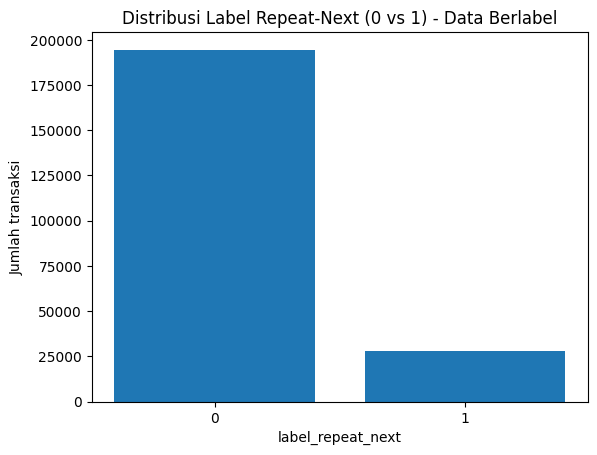

In [61]:
label_col = "label_repeat_next"

vc_all = df[label_col].value_counts(dropna=False)
print("Distribusi label (termasuk NaN):")
display(vc_all)

df_labeled = df[df[label_col].notna()].copy()
df_labeled[label_col] = df_labeled[label_col].astype(int)

vc = df_labeled[label_col].value_counts().sort_index()
repeat_rate = df_labeled[label_col].mean()

print("Jumlah data berlabel:", len(df_labeled))
print(f"Repeat rate (label=1): {repeat_rate:.4f}")

plt.figure()
plt.bar(vc.index.astype(str), vc.values)
plt.title("Distribusi Label Repeat-Next (0 vs 1) - Data Berlabel")
plt.xlabel("label_repeat_next")
plt.ylabel("Jumlah transaksi")
plt.show()
plt.close("all")

<h3>EDA Cell 2 - Ringkasan Dataset & Cakupan Waktu</h3>
<p>
Pada cell ini kami membuat ringkasan cepat terkait struktur dataset:
jumlah kolom, beberapa contoh nilai, serta perkiraan cakupan waktu transaksi.
Tujuannya untuk memastikan data masuk akal sebelum masuk ke analisis kategori dan numerik.
</p>

In [62]:
print("Shape (all):", df.shape)
print("Shape (labeled):", df_labeled.shape)

candidate_date_cols = [
    c for c in df.columns
    if any(k in c.lower() for k in ["tgl", "date", "tanggal"])
]
print("Candidate date columns:", candidate_date_cols)

if "tgl mohon" in df.columns:
    tmp_dt = pd.to_datetime(df["tgl mohon"], errors="coerce")
    print("Cakupan tgl mohon:", tmp_dt.min(), "->", tmp_dt.max())

display(df_labeled.sample(5, random_state=42))

Shape (all): (319978, 30)
Shape (labeled): (222314, 30)
Candidate date columns: ['tgl lahir', 'tgl cetak', 'tgl mohon', 'max_tgl_mohon_customer']
Cakupan tgl mohon: 2019-01-02 00:00:00 -> 2025-12-31 00:00:00


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,agama,pekerjaan,umur,dp aktual,cicilan,warna,dealer,type series,range dp,wilayah,9 segment,kode motor,otr,tahun rakit,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer
152869,CUST-14365,BATU AMPAR,BALIKPAPAN UTARA,76136,2.0,126157.0,1,2,1,2001-01-18,1,2c,220.0,47000000.0,13500000.0,BK,Balikpapan,GENEX SERIES,3 juta up,6471,AT LOW,LB,212900000.0,2023,NaN,NaN,2023-01-18,6471-6400,0,2023-01-18
268260,CUST-183236,GUNUNG SARI ULU,BALIKPAPAN TENGAH,76122,2.0,733.0,1,2,1,1998-08-10,1,2e,27.0,3600000.0,2000000.0,SV,Balikpapan,PXE,3 juta up,6471,AT HIGH,LT,35700000.0,2024,NaN,NaN,2024-12-31,6471-6400,0,2024-12-31
131703,CUST-207410,KLANDASAN ILIR,BALIKPAPAN KOTA,76113,2.0,13115.0,1,2,1,1985-12-29,1,4f,37.0,40000000.0,13500000.0,BK,Balikpapan,SCOOTY SERIES,3 jt up,6471,AT MID,LR,23710000.0,2022,NaN,NaN,2022-08-10,6471-6400,0,2022-08-10
26629,CUST-246473,Juata Permai,Tarakan Utara,77116,1.0,16609.0,N,N,2,2001-09-11,1,5,18.0,0.0,0.0,BL,Tarakan,VAREX 150,krg 1 juta,6571,AT HIGH,HY,25350000.0,2019.0,NaN,NaN,2019-08-19,6571-6500,0,2019-08-19
300813,CUST-68134,DUMARING,TALISAYAN,77372,1.0,2834.0,N,N,1,1988-12-22,3,2e,37.0,0.0,0.0,BR,Berau,RYVO SERIES,krg 1 jt,6405.0,CUB LOW,GD,15599000.0,2025,NaN,NaN,2025-08-13,6405-6400,0,2025-08-13


<h3>EDA Cell 3 - Missing Value & Kualitas Data</h3>
<p>
Kami memeriksa missing values pada data berlabel untuk mengidentifikasi fitur yang
membutuhkan imputasi, pembersihan, atau perlu di-drop pada modeling.
Output disajikan sebagai tabel persentase missing agar mudah diprioritaskan.
</p>

In [63]:
missing = (df_labeled.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
print("Kolom yang memiliki missing value (%):")
display(missing.to_frame("missing_pct"))

Kolom yang memiliki missing value (%):


,missing_pct
tgl cetak,100.000000
dlr group,80.945420
tahun rakit,4.451362
dp aktual,0.191171
cicilan,0.172279
finance company,0.031937
kode motor,0.017543
tenor,0.005848
otr,0.001799
kelurahan,0.000450


<h3>EDA Cell 4 - Normalisasi Kategori (Strip + Normalisasi ID-like)</h3>
<p>
Sebelum melakukan analisis repeat rate per kategori, kami menormalkan nilai pada fitur kategorikal:
menghapus spasi berlebih (<i>strip</i>) dan menyederhanakan kolom yang bersifat ID-like
(misal: kode dealer, kode cabang, kode mitra) agar lebih konsisten.
</p>
<p>
Tujuannya adalah mengurangi fragmentasi kategori akibat variasi format penulisan
(seperti spasi, huruf besar/kecil, atau tanda baca) yang dapat mengganggu interpretasi statistik.
</p>

In [ ]:
def normalize_id_like(series: pd.Series) -> pd.Series:
    s = series.astype("string")
    s = s.str.strip()
    s = s.str.lower()
    s = s.str.replace(r"\s+", " ", regex=True)
    s = s.str.replace(r"[^\w\s\-\/]", "", regex=True)
    return s

cat_fix_cols = [c for c in df_labeled.columns if df_labeled[c].dtype == "object"]
cat_fix_cols = [c for c in cat_fix_cols if c not in [label_col]]

id_like_cols = [c for c in cat_fix_cols if any(k in c.lower() for k in ["id", "kode", "code", "no", "dealer", "branch", "cabang"])]
id_like_cols = [c for c in id_like_cols if "tenor" not in c.lower()]
# 1) strip dasar untuk semua kategori
for c in cat_fix_cols:
    df_labeled[c] = df_labeled[c].astype("string").str.strip()

# 2) normalisasi lebih kuat untuk ID-like
for c in id_like_cols:
    df_labeled[c] = normalize_id_like(df_labeled[c])

print("Jumlah kolom kategori dibersihkan:", len(cat_fix_cols))
print("Kolom yang dianggap ID-like:", id_like_cols[:20], "..." if len(id_like_cols) > 20 else "")

for c in id_like_cols[:5]:
    print(f"\nTop kategori untuk: {c}")
    display(df_labeled[c].value_counts(dropna=False).head(10))

Jumlah kolom kategori dibersihkan: 23
Kolom yang dianggap ID-like: ['customer id', 'kode pos', 'dealer', 'kode motor', 'kode kota-provinsi'] 

Top kategori untuk: customer id


customer id
cust-266618    247
cust-266623    242
cust-266564    211
cust-05206     168
cust-05116     149
cust-05078     123
cust-265993     99
cust-266005     92
cust-266539     84
cust-03220      77
Name: count, dtype: Int64


Top kategori untuk: kode pos


kode pos
76115    11269
76251     9615
77315     9273
76114     8474
76116     8184
76125     8000
77111     6388
77212     6288
77482     6146
77371     5712
Name: count, dtype: Int64


Top kategori untuk: dealer


dealer
balikpapan    89272
berau         34830
paser         32477
tarakan       23965
ppu           19240
bulungan      14344
nunukan        8186
Name: count, dtype: Int64


Top kategori untuk: kode motor


kode motor
hr    19245
lp    15274
lr    15157
lm    12215
ll    10968
lx    10558
lj     7031
mo     6845
lb     6771
eu     6578
Name: count, dtype: Int64


Top kategori untuk: kode kota-provinsi


kode kota-provinsi
6471-6400    80610
6405-6400    34510
6401-6400    33290
6571-6500    21640
6409-6400    21293
6502-6500    13963
6504-6500     9114
6403-6400     3101
6503-6500     1292
6472-6400      987
Name: count, dtype: Int64

<h3>EDA Cell 5 - Repeat Rate per Kategori (Fokus Kolom Utama)</h3>
<p>
Kami menghitung repeat rate (<code>mean(label_repeat_next)</code>) untuk beberapa fitur kategori utama.
Agar insight tidak menjadi sekadar dump tabel, kami membatasi analisis pada kolom-kolom yang paling relevan
dan menerapkan filter <code>min_n</code> sehingga kategori yang terlalu jarang tidak mendistorsi interpretasi.
</p>
<p>
Output diambil <b>Top-N</b> kategori dengan jumlah data memadai dan repeat rate yang informatif.
Kolom kategori lain dapat dianalisis sebagai lampiran bila diperlukan.
</p>

In [ ]:
def repeat_rate_by(col: str, min_n: int = 200) -> pd.DataFrame:
    tmp = df_labeled.groupby(col)[label_col].agg(["count", "mean"]).reset_index()
    tmp = tmp.rename(columns={"count": "n", "mean": "repeat_rate"})
    tmp = tmp[tmp["n"] >= min_n].sort_values(["repeat_rate", "n"], ascending=[False, False])
    tmp["repeat_rate_pct"] = (tmp["repeat_rate"] * 100).round(2)
    return tmp

candidate_focus = [
    "9 segment", "dealer", "finance company", "wilayah", "tenor"
]
focus_cols = [c for c in candidate_focus if c in df_labeled.columns]

print("Kolom kategori fokus yang ditemukan:", focus_cols)

for col in focus_cols:
    print("\n=== Repeat rate by:", col, "===")
    tab = repeat_rate_by(col, min_n=200)
    display(tab.head(10))

Kolom kategori fokus yang ditemukan: ['9 segment', 'dealer', 'finance company', 'wilayah', 'tenor']

=== Repeat rate by: 9 segment ===


,9 segment,n,repeat_rate,repeat_rate_pct
8,SPORT LOW,6794,0.463939,46.39
4,CUB LOW,6395,0.260360,26.04
9,SPORT MID,9129,0.170884,17.09
3,CUB HIGH,1815,0.169146,16.91
5,CUB MID,4512,0.165559,16.56
1,AT LOW,79011,0.110314,11.03
2,AT MID,76160,0.103020,10.30
0,AT HIGH,38218,0.098383,9.84



=== Repeat rate by: dealer ===


,dealer,n,repeat_rate,repeat_rate_pct
0,balikpapan,89272,0.142150,14.21
1,berau,34830,0.134941,13.49
6,tarakan,23965,0.118381,11.84
5,ppu,19240,0.105665,10.57
4,paser,32477,0.101456,10.15
2,bulungan,14344,0.100600,10.06
3,nunukan,8186,0.097728,9.77



=== Repeat rate by: finance company ===


,finance company,n,repeat_rate,repeat_rate_pct
1,11,4988,0.156375,15.64
5,2,10118,0.145977,14.60
3,13,1125,0.131556,13.16
8,3,2458,0.130594,13.06
15,N,97309,0.128272,12.83
0,1,92857,0.122619,12.26
14,9,1288,0.118012,11.80
11,4,6457,0.091683,9.17
9,36,734,0.081744,8.17
7,26,340,0.079412,7.94



=== Repeat rate by: wilayah ===


,wilayah,n,repeat_rate,repeat_rate_pct
194,6402,252,0.535714,53.57
212,6501,549,0.411658,41.17
198,6404,778,0.244216,24.42
200,6405,30154,0.151025,15.10
206,6471,72822,0.150271,15.03
202,6409,18770,0.139531,13.95
220,6571,19702,0.127094,12.71
214,6502,12119,0.122040,12.20
192,6401,29131,0.113178,11.32
218,6504,7756,0.110237,11.02



=== Repeat rate by: tenor ===


,tenor,n,repeat_rate,repeat_rate_pct
0,1,26664,0.161679,16.17
6,N,97341,0.128137,12.81
1,2,75523,0.118679,11.87
2,3,22647,0.088974,8.90


<h3>EDA Cell 6 - Insight Numerik (Distribusi & Perbandingan per Label)</h3>
<p>
Kami menganalisis fitur numerik dengan membandingkan statistik ringkas antara label <b>0</b> dan <b>1</b>,
serta memvisualisasikan distribusi melalui boxplot.
Sebelum analisis, fitur numerik yang tersimpan sebagai <i>object</i> akan dicoba dikonversi menjadi numeric.
</p>
<p>
Untuk menghindari duplikasi, variabel seperti <code>tenor</code> diperlakukan sebagai kategori pada Cell 5,
sehingga Cell ini fokus pada nilai numerik kontinu (misalnya: dp, cicilan, umur, otr, dll).
</p>

Kolom numerik yang dianalisis: ['umur', 'dp aktual', 'cicilan', 'range dp', 'otr']


,count_0,mean_0,median_0,std_0,count_1,mean_1,median_1,std_1
umur,194516.0,84.849938,38.0,125.096508,27798.0,78.243651,38.0,117.998363
dp aktual,194167.0,15847115.008163,2100000.0,49656367.338381,27722.0,21241569.63823,6000000.0,182697030.630292
cicilan,194204.0,8140135.455655,1435000.0,351217848.368729,27727.0,10086798.256321,2450000.0,183271439.601213
range dp,0.0,<NA>,<NA>,<NA>,0.0,<NA>,<NA>,<NA>
otr,194514.0,58660618.553009,23160000.0,84064870.515295,27796.0,51513680.961289,22070000.0,77417055.739312


<Figure size 640x480 with 0 Axes>

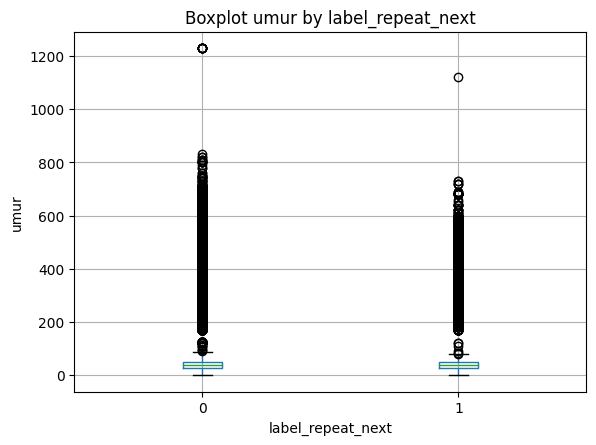

<Figure size 640x480 with 0 Axes>

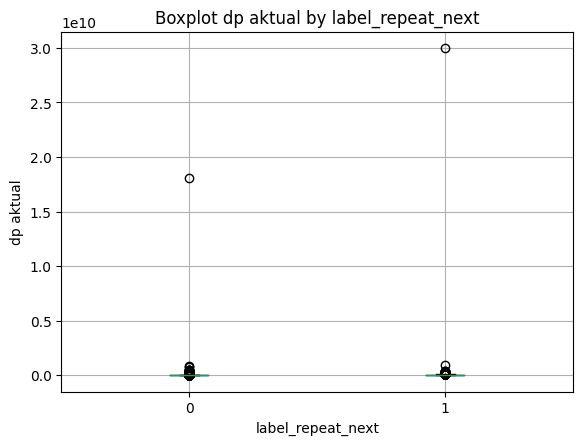

<Figure size 640x480 with 0 Axes>

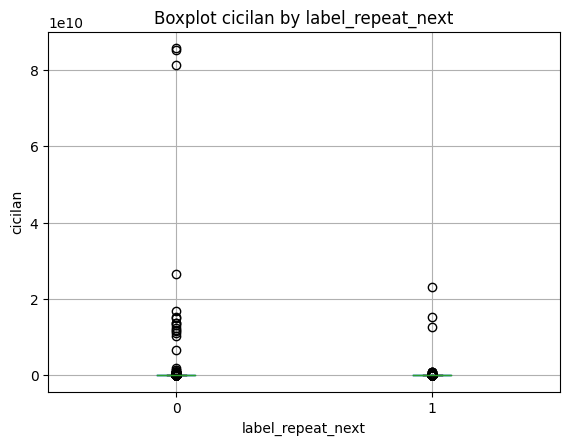

<Figure size 640x480 with 0 Axes>

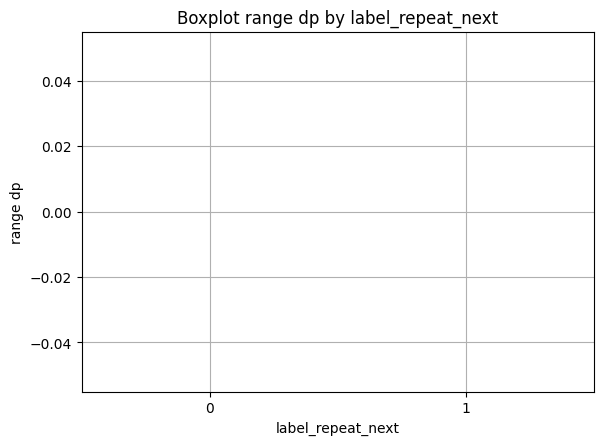

<Figure size 640x480 with 0 Axes>

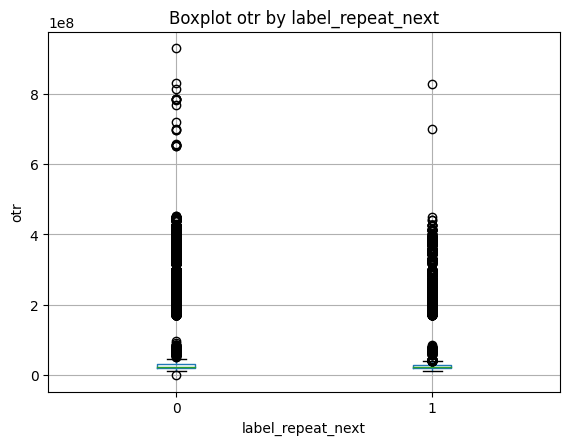

In [ ]:

numeric_candidates = [
    "dp", "cicilan", "otr", "umur", "harga", "down payment", "installment"
]


num_cols = [c for c in df_labeled.columns if any(k in c.lower() for k in ["dp", "cicil", "otr", "umur", "harga"])]
num_cols = [c for c in num_cols if "tenor" not in c.lower()]

for c in num_cols:
    df_labeled[c] = pd.to_numeric(df_labeled[c], errors="coerce")

print("Kolom numerik yang dianalisis:", num_cols)


if len(num_cols) > 0:
    stats_0 = df_labeled[df_labeled[label_col] == 0][num_cols].describe().T
    stats_1 = df_labeled[df_labeled[label_col] == 1][num_cols].describe().T

    stats = stats_0[["count", "mean", "50%", "std"]].rename(
        columns={"count": "count_0", "mean": "mean_0", "50%": "median_0", "std": "std_0"}
    ).join(
        stats_1[["count", "mean", "50%", "std"]].rename(
            columns={"count": "count_1", "mean": "mean_1", "50%": "median_1", "std": "std_1"}
        )
    )

    display(stats)

    show_cols = num_cols[:6]
    for c in show_cols:
        plt.figure()
        df_labeled.boxplot(column=c, by=label_col)
        plt.title(f"Boxplot {c} by label_repeat_next")
        plt.suptitle("")
        plt.xlabel("label_repeat_next")
        plt.ylabel(c)
        plt.show()
else:
    print("Tidak ada kolom numerik kandidat yang terdeteksi. Silakan sesuaikan list num_cols.")

<h3>EDA Cell 7 - Analisis Repeat per Customer</h3>
<p>
Kami mengecek apakah label repeat-next berkorelasi dengan perilaku pelanggan yang sering bertransaksi.
Dengan menghitung jumlah transaksi per customer dan menghubungkannya dengan repeat rate,
kita dapat melihat apakah pelanggan dengan aktivitas tinggi cenderung memiliki peluang repeat yang berbeda.
</p>

In [ ]:
candidate_customer_cols = [
    c for c in df_labeled.columns
    if any(k in c.lower() for k in ["customer", "cust", "pelanggan", "nik", "ktp"])
    and "max_" not in c.lower()
    and "tgl" not in c.lower()
]
print("Candidate customer id columns:", candidate_customer_cols)

customer_col = candidate_customer_cols[0] if len(candidate_customer_cols) > 0 else None

if customer_col is None:
    print("Kolom customer id tidak terdeteksi. Silakan set manual customer_col.")
else:
    cust_tab = df_labeled.groupby(customer_col)[label_col].agg(["count", "mean"]).reset_index()
    cust_tab = cust_tab.rename(columns={"count": "n_tx", "mean": "repeat_rate"})
    cust_tab["repeat_rate_pct"] = (cust_tab["repeat_rate"] * 100).round(2)

    display(cust_tab.sort_values("n_tx", ascending=False).head(20))

    cust_tab["tx_bin"] = pd.cut(cust_tab["n_tx"], bins=[1,2,3,5,10,20,50,100,10_000], right=True)
    bin_tab = cust_tab.groupby("tx_bin")["repeat_rate"].agg(["count", "mean"]).reset_index()
    bin_tab["repeat_rate_pct"] = (bin_tab["mean"] * 100).round(2)

    display(bin_tab)

Candidate customer id columns: ['customer id']


,customer id,n_tx,repeat_rate,repeat_rate_pct
138786,cust-266618,247,0.878543,87.85
138792,cust-266623,242,0.888430,88.84
138736,cust-266564,211,0.971564,97.16
3875,cust-05206,168,0.988095,98.81
3800,cust-05116,149,0.919463,91.95
3766,cust-05078,123,0.910569,91.06
138262,cust-265993,99,0.989899,98.99
138273,cust-266005,92,0.934783,93.48
138715,cust-266539,84,0.809524,80.95
2424,cust-03220,77,0.987013,98.70


,tx_bin,count,mean,repeat_rate_pct
0,"(1, 2]",16374,0.486717,48.67
1,"(2, 3]",2159,0.635943,63.59
2,"(3, 5]",742,0.670350,67.04
3,"(5, 10]",254,0.657463,65.75
4,"(10, 20]",107,0.697284,69.73
5,"(20, 50]",61,0.848310,84.83
6,"(50, 100]",10,0.914661,91.47
7,"(100, 10000]",6,0.926111,92.61


<h3>EDA Cell 7B - Appendix: Debug Customer Ekstrem</h3>
<p>
Sebagai lampiran, kami mengambil beberapa customer dengan transaksi terbanyak untuk memastikan tidak ada anomali ekstrim.
Kami hanya menampilkan contoh <b>10 baris</b> agar tidak membanjiri notebook.
Jika ditemukan pola aneh (misalnya transaksi banyak dalam satu hari), hal ini akan menjadi catatan untuk cleaning/modeling.
</p>

In [68]:
if customer_col is None:
    print("Skip: customer_col tidak tersedia.")
else:
    top_customers = cust_tab.sort_values("n_tx", ascending=False)[customer_col].head(3).tolist()
    print("Top customers (by n_tx):", top_customers)

    cols_show = [customer_col, label_col] + [c for c in df_labeled.columns if "date" in c.lower() or "tanggal" in c.lower()]
    cols_show = list(dict.fromkeys([c for c in cols_show if c in df_labeled.columns]))  # unique + exist

    for cid in top_customers:
        print(f"\n--- Sample rows for customer: {cid} ---")
        display(df_labeled[df_labeled[customer_col] == cid][cols_show].head(10))

Top customers (by n_tx): ['cust-266618', 'cust-266623', 'cust-266564']

--- Sample rows for customer: cust-266618 ---


,customer id,label_repeat_next
93748,cust-266618,1
93749,cust-266618,1
93750,cust-266618,1
93751,cust-266618,1
93752,cust-266618,1
93753,cust-266618,1
93754,cust-266618,1
93755,cust-266618,1
93756,cust-266618,1
93757,cust-266618,1



--- Sample rows for customer: cust-266623 ---


,customer id,label_repeat_next
92483,cust-266623,1
92484,cust-266623,1
92485,cust-266623,1
92486,cust-266623,1
92487,cust-266623,1
92488,cust-266623,1
92489,cust-266623,1
92490,cust-266623,1
92491,cust-266623,1
92492,cust-266623,1



--- Sample rows for customer: cust-266564 ---


,customer id,label_repeat_next
142412,cust-266564,1
142413,cust-266564,1
142414,cust-266564,1
142415,cust-266564,1
142416,cust-266564,1
142417,cust-266564,1
142418,cust-266564,1
142419,cust-266564,1
142420,cust-266564,1
142421,cust-266564,1


# MODELING BASELINE

<h3>Cell 0 - Import & Load Data</h3>
<p>
Pada cell ini, kami melakukan import library inti (pandas/numpy/matplotlib + scikit-learn) dan memuat dataset hasil labeling dari file <code>sparc_labeled.csv</code> yang berada satu folder dengan notebook. Tujuannya memastikan pipeline modeling berjalan dari dataset yang sudah memiliki target <code>label_repeat_next</code>.
</p>
<p>
Output awal seperti <code>Shape</code> dan preview baris digunakan untuk sanity check bahwa file yang dipakai sudah benar (bukan CSV mentah) dan kolom-kolom penting tersedia.
</p>

In [10]:
# Cell 0 — Import & Load Data
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
print("Labeled CSV path:", labeled_path)

df = pd.read_csv(labeled_path)
print("Shape:", df.shape)
df.head()

Labeled CSV path: c:\Patrick\coding\save later\sparc\sparc_labeled.csv
Shape: (319978, 34)


C:\Users\timot\AppData\Local\Temp\ipykernel_10688\1564193850.py:24: DtypeWarning: Columns (3,19,23,24,25,26,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(labeled_path)


,customer id,kelurahan,kecamatan,kode pos,cash/credit,kode dealer,finance company,tenor,gender,tgl lahir,...,dlr group,tgl cetak,tgl mohon,kode kota-provinsi,label_repeat_next,max_tgl_mohon_customer,mohon_year,mohon_month,mohon_dow,mohon_quarter
0,cust-159769,Baru Ilir,Balikpapan Barat,76131,2.0,12756.0,4,3,2,1992-03-03,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0
1,cust-164551,BARU TENGAH,BALIKPAPAN BARAT,76132,2.0,733.0,1,1,2,1991-04-27,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0
2,cust-159733,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1982-04-01,...,NaN,NaN,2019-01-02,6471-6400,1.0,2020-08-25,2019.0,1.0,2.0,1.0
3,cust-164422,BARU TENGAH,BALIKPAPAN BARAT,76132,1.0,733.0,N,N,2,1997-06-26,...,NaN,NaN,2019-01-02,6471-6400,1.0,2022-05-12,2019.0,1.0,2.0,1.0
4,cust-155472,Baru Ulu,Balikpapan Barat,76133,2.0,11160.0,1,2,1,1996-12-07,...,NaN,NaN,2019-01-02,6471-6400,0.0,2019-01-02,2019.0,1.0,2.0,1.0


<h3>Cell 1 - Casting Tanggal & Filter Data Berlabel</h3>
<p>
Pada cell ini, kami memastikan kolom <code>tgl mohon</code> bertipe datetime (karena dipakai untuk split berbasis waktu). Setelah itu, kami memfilter hanya baris yang memiliki target <code>label_repeat_next</code> (tidak NaN).
</p>
<p>
Alasan filtering: baris tanpa label umumnya disebabkan <code>tgl mohon</code> kosong sehingga transaksi tersebut tidak dapat diurutkan dalam waktu, sehingga target time-aware tidak bisa dibentuk secara valid. Dengan demikian, dataset untuk modeling menjadi subset yang “well-defined” untuk evaluasi.
</p>

In [11]:
# Cell 1 — Cast tipe tanggal + filter data berlabel

if "label_repeat_next" not in df.columns:
    raise ValueError("Kolom label_repeat_next tidak ditemukan. Pastikan labeling sudah disave ke sparc_labeled.csv")

if "tgl mohon" in df.columns:
    df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")
else:
    raise ValueError("Kolom 'tgl mohon' tidak ditemukan. Kita butuh ini untuk time-based split.")

# pakai hanya baris yang punya label (drop NaN)
df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows total:", df.shape[0])
print("Rows berlabel untuk modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")

print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

Rows total: 319978
Rows berlabel untuk modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split</h3>
<p>
Cell ini melakukan pemisahan data train dan test secara time-based: 80% tanggal paling awal untuk train dan 20% tanggal paling akhir untuk test. Pendekatan ini dibuat agar evaluasi lebih realistis (melatih dari histori dan menguji pada periode masa depan), sekaligus menghindari leakage.
</p>
<p>
Perbedaan repeat rate train vs test dapat terjadi (label shift) karena definisi label “ada transaksi setelah tanggal ini” secara alami akan menurun pada periode mendekati ujung data (right-censoring). Oleh karena itu, metrik threshold-independent seperti ROC-AUC dan PR-AUC diprioritaskan.
</p>

In [12]:
# Cell 2 — Time-based split
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)

# split: 80% awal untuk train, 20% akhir untuk test
split_idx = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_idx].copy()
test_df  = df_model.iloc[split_idx:].copy()

print("Train period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])

y_train = train_df["label_repeat_next"].values
y_test  = test_df["label_repeat_next"].values

print("Train repeat rate:", round(y_train.mean() * 100, 2), "%")
print("Test repeat rate :", round(y_test.mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Feature Selection</h3>
<p>
Cell ini adalah revisi penting dari versi baseline awal. Pada percobaan sebelumnya, kolom tanggal mentah
(<code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code>) masih ikut menjadi fitur dan berisiko diperlakukan sebagai kategori oleh
OneHotEncoder, yang dapat membuat model kurang stabil.
</p>
<p>
Pada versi terbaru, tahap <i>feature engineering</i> untuk waktu sudah dilakukan lebih awal pada tahap
<b>Preprocessing & Feature Engineering</b> (sebelum data disimpan ke CSV). Karena itu, di baseline modeling ini kami hanya melakukan
<b>seleksi fitur</b> dengan cara:
</p>
<ul>
  <li>menghapus kolom datetime mentah agar tidak ikut masuk ke encoder,</li>
  <li>menghapus kolom helper/leakage dari proses labeling (mis. <code>max_tgl_mohon_customer</code>),</li>
  <li>menghapus kolom ID seperti <code>customer id</code> agar model baseline tidak “menghafal” identitas.</li>
</ul>
<p>
Fitur waktu turunan yang aman dan informatif (<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, <code>mohon_quarter</code>)
sudah tersedia di dataset hasil preprocessing, sehingga tetap digunakan sebagai fitur tanpa perlu dibuat ulang di sini.
</p>
<p>
Hasil akhir cell ini adalah <code>X_train_raw</code> dan <code>X_test_raw</code> yang berisi fitur siap diproses,
tanpa kolom leakage/helper serta tanpa kolom datetime mentah.
</p>

In [13]:
# Cell 3 Feature selection

drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
]

# drop kolom datetime mentah supaya tidak ikut OHE
datetime_raw_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in train_df.columns]

drop_cols = [c for c in drop_cols if c in train_df.columns] + datetime_raw_cols

X_train_raw = train_df.drop(columns=drop_cols)
X_test_raw = test_df.drop(columns=drop_cols)

print("Dropped:", drop_cols)
print("X_train shape:", X_train_raw.shape)
print("X_test shape :", X_test_raw.shape)

# QC kecil: pastikan fitur waktu memang ada
need_time = ["mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"]
print("Time features exist:", {c: (c in X_train_raw.columns) for c in need_time})

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train shape: (177851, 28)
X_test shape : (44463, 28)
Time features exist: {'mohon_year': True, 'mohon_month': True, 'mohon_dow': True, 'mohon_quarter': True}


<h3>Cell 4 - Tentukan Fitur Numerik vs Kategorikal</h3>
<p>
Cell ini menyiapkan pemisahan fitur numerik dan kategorikal. Kolom numerik (mis. <code>dp aktual</code>, <code>cicilan</code>, <code>otr</code>, <code>umur</code>, dll) di-cast menjadi numeric dengan <code>errors="coerce"</code> agar nilai anomali berubah menjadi NaN dan bisa diimputasi.
</p>
<p>
Revisi utama di sini adalah normalisasi tipe pada kolom kategorikal: seluruh nilai dikonversi menjadi string yang bersih (strip whitespace), sementara missing tetap NaN. Ini menghindari error encoder terkait tipe campuran (mis. integer bercampur string) dan memastikan OneHotEncoder menerima input yang konsisten.
</p>

In [14]:
# Cell 4 - Tentukan num/cat + clean kategori seragam string

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train_raw.columns]

for c in num_cols:
    X_train_raw[c] = pd.to_numeric(X_train_raw[c], errors="coerce")
    X_test_raw[c] = pd.to_numeric(X_test_raw[c], errors="coerce")

cat_cols = [c for c in X_train_raw.columns if c not in num_cols]

def to_clean_string(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return np.nan
    if isinstance(v, str):
        s = v.strip()
        return np.nan if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train_raw[c] = X_train_raw[c].map(to_clean_string).astype(object)
    X_test_raw[c] = X_test_raw[c].map(to_clean_string).astype(object)

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18


<h3>Cell 5 - Preprocessing Pipeline & Dua Baseline Model</h3>
<p>
Cell ini membangun pipeline preprocessing menggunakan <code>ColumnTransformer</code>:
</p>
<ul>
  <li>
    <b>Numerik:</b> imputasi median + <code>StandardScaler</code> untuk menstabilkan logistic regression (membuat koefisien lebih interpretable dan optimisasi lebih baik).
  </li>
  <li>
    <b>Kategorikal:</b> imputasi konstanta <code>"MISSING"</code> + OneHotEncoder dengan <code>min_frequency=50</code> agar kategori yang sangat jarang tidak meledakkan dimensi fitur.
  </li>
</ul>
<p>
Pada baseline modeling, kami melatih dua varian logistic regression:
</p>
<ul>
  <li><b>Vanilla:</b> tanpa <code>class_weight</code>, sebagai baseline standar.</li>
  <li><b>Balanced:</b> dengan <code>class_weight="balanced"</code>, untuk membandingkan trade-off recall vs precision pada data tidak seimbang.</li>
</ul>
<p>
Perbandingan dua model ini membuat hasil lebih kuat untuk laporan: baseline tidak hanya satu angka, tetapi menunjukkan efek strategi penanganan imbalance.
</p>

In [15]:
# Cell 5 - Preprocess + 2 Baseline LR (vanilla & balanced)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()) 
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

lr_vanilla = LogisticRegression(
    max_iter=400,
    random_state=RANDOM_SEED
)

lr_balanced = LogisticRegression(
    max_iter=400,
    random_state=RANDOM_SEED,
    class_weight="balanced"
)

baseline_vanilla = Pipeline(steps=[("preprocess", preprocess), ("model", lr_vanilla)])
baseline_balanced = Pipeline(steps=[("preprocess", preprocess), ("model", lr_balanced)])

baseline_vanilla, baseline_balanced

(Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['dp aktual', 'cicilan',
                                                    'otr', 'umur', 'tahun rakit',
                                                    'tenor', 'mohon_year',
                                                    'mohon_month', 'mohon_dow',
                                                    'mohon_quarter']),
                                                  ('cat',
                                                   Pipeline(steps=[('imputer',
                                        

<h3>Cell 6 - Training & Probabilitas Prediksi</h3>
<p>
Cell ini melakukan training untuk kedua baseline model dan menampilkan ringkasan distribusi probabilitas prediksi (min/mean/max). Ringkasan ini berfungsi sebagai quality check:
</p>
<ul>
  <li>Jika probabilitas terlalu sempit dan berkumpul di ~0.5, model biasanya tidak belajar signal (atau fitur tidak benar).</li>
  <li>Jika probabilitas lebih tersebar, model berpotensi menangkap pola yang relevan.</li>
</ul>
<p>
Pada revisi ini, distribusi probabilitas menjadi lebih masuk akal dibanding versi awal yang hampir konstan, yang menunjukkan perbaikan feature handling dan preprocessing berhasil.
</p>

In [16]:
# Cell 6— Train + proba summary

baseline_vanilla.fit(X_train_raw, y_train)
proba_vanilla = baseline_vanilla.predict_proba(X_test_raw)[:, 1]

baseline_balanced.fit(X_train_raw, y_train)
proba_balanced = baseline_balanced.predict_proba(X_test_raw)[:, 1]

print("Vanilla proba min/mean/max:",
      float(np.min(proba_vanilla)), float(np.mean(proba_vanilla)), float(np.max(proba_vanilla)))
print("Balanced proba min/mean/max:",
      float(np.min(proba_balanced)), float(np.mean(proba_balanced)), float(np.max(proba_balanced)))

Vanilla proba min/mean/max: 0.0020087595117244256 0.06036661837860437 0.8398542453196749
Balanced proba min/mean/max: 0.013205204640539618 0.21946898820645422 0.9651670541389681


<h3>Cell 7 — Evaluasi (ROC-AUC, PR-AUC, F1, Confusion Matrix) + ROC/PR Curve </h3>
<p>
Cell ini mengevaluasi kedua model baseline menggunakan metrik yang sesuai untuk kasus klasifikasi tidak seimbang:
</p>
<ul>
  <li><b>ROC-AUC</b> sebagai metrik utama threshold-independent.</li>
  <li><b>PR-AUC (Average Precision)</b> untuk menilai performa pada kelas positif yang minoritas.</li>
  <li><b>F1 @ threshold 0.5</b> dan <b>Confusion Matrix</b> untuk interpretasi operasional.</li>
</ul>
<p>
Perbandingan yang umum terlihat:
</p>
<ul>
  <li><b>Vanilla</b> cenderung lebih konservatif: precision lebih tinggi tetapi recall lebih rendah.</li>
  <li><b>Balanced</b> cenderung lebih agresif: recall naik tetapi precision turun.</li>
</ul>
<p>
Plot ROC dan PR curve membantu memvisualisasikan performa secara menyeluruh tanpa bergantung pada satu threshold.
</p>


Baseline LR (Vanilla)
ROC-AUC: 0.793
PR-AUC : 0.2951
F1@0.5 : 0.2711
Confusion Matrix @0.5:
 [[42658   164]
 [ 1358   283]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9691    0.9962    0.9825     42822
           1     0.6331    0.1725    0.2711      1641

    accuracy                         0.9658     44463
   macro avg     0.8011    0.5843    0.6268     44463
weighted avg     0.9567    0.9658    0.9562     44463



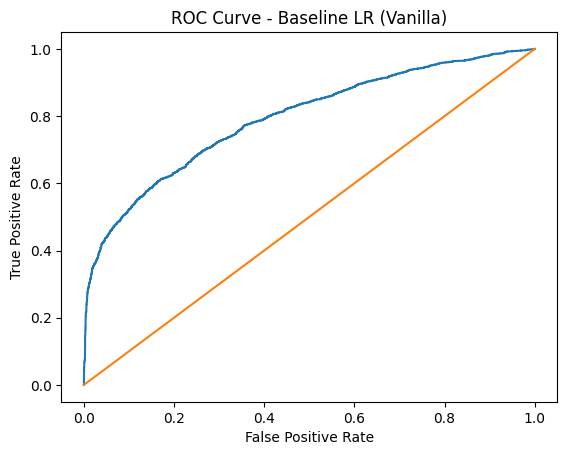

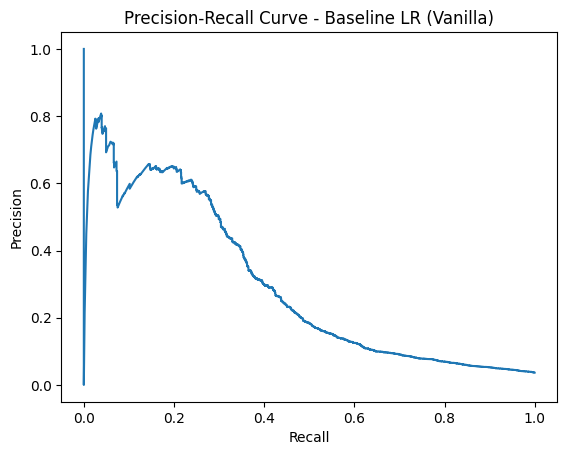


Baseline LR (Balanced)
ROC-AUC: 0.7922
PR-AUC : 0.288
F1@0.5 : 0.3565
Confusion Matrix @0.5:
 [[41688  1134]
 [ 1039   602]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9757    0.9735    0.9746     42822
           1     0.3468    0.3668    0.3565      1641

    accuracy                         0.9511     44463
   macro avg     0.6612    0.6702    0.6656     44463
weighted avg     0.9525    0.9511    0.9518     44463



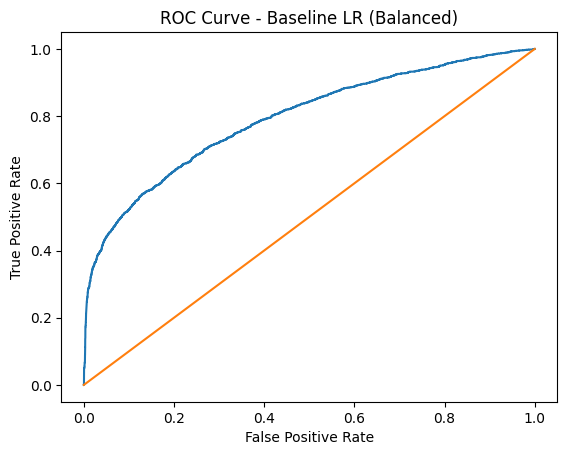

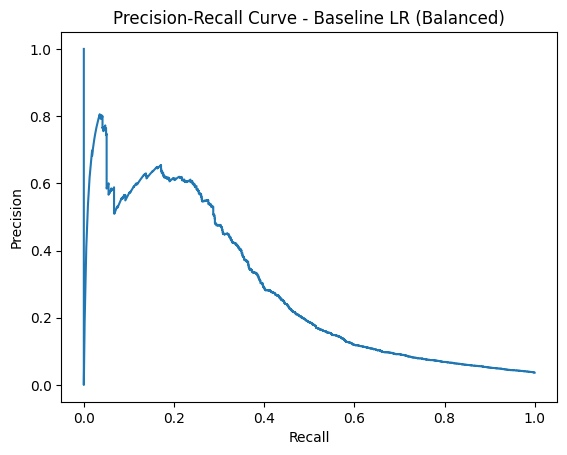

In [17]:
# Cell 7 — Evaluation helper + plot
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

def evaluate_probs(y_true, y_proba, title="Model"):
    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)

    # threshold 0.5
    y_pred_05 = (y_proba >= 0.5).astype(int)
    f1_05 = f1_score(y_true, y_pred_05)

    print("\n==============================")
    print(title)
    print("ROC-AUC:", round(roc_auc, 4))
    print("PR-AUC :", round(pr_auc, 4))
    print("F1@0.5 :", round(f1_05, 4))
    print("Confusion Matrix @0.5:\n", confusion_matrix(y_true, y_pred_05))
    print("\nReport @0.5:\n", classification_report(y_true, y_pred_05, digits=4))

    # ROC
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    plt.figure()
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1])
    plt.title(f"ROC Curve - {title}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.show()

    # PR
    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    plt.figure()
    plt.plot(rec, prec)
    plt.title(f"Precision-Recall Curve - {title}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.show()

evaluate_probs(y_test, proba_vanilla, "Baseline LR (Vanilla)")
evaluate_probs(y_test, proba_balanced, "Baseline LR (Balanced)")

<h3>Cell 8 - Interpretasi Model: Top Coefficients</h3>
<p>
Cell ini mengekstrak nama fitur setelah preprocessing (numerik + hasil OneHotEncoder) lalu menggabungkannya dengan koefisien logistic regression untuk interpretasi.
</p>
<p>
Kami menampilkan:
</p>
<ul>
  <li><b>Top abs coefficients</b>: fitur yang paling berpengaruh secara magnitude.</li>
  <li><b>Top positif</b>: fitur yang meningkatkan peluang repeat.</li>
  <li><b>Top negatif</b>: fitur yang menurunkan peluang repeat.</li>
</ul>
<p>
Catatan penting: karena OneHotEncoder menggunakan <code>min_frequency</code>, kategori langka dapat digabung menjadi fitur seperti <code>..._infrequent_sklearn</code>. Ini adalah desain untuk menjaga dimensi fitur tetap terkontrol dan justru membuat baseline lebih stabil.
</p>
<p>
Output koefisien ini dapat dipakai sebagai bahan narasi laporan untuk menjelaskan fitur/segmen mana yang terkait dengan repeat order, dengan catatan bahwa koefisien logistic menunjukkan korelasi (bukan kausalitas).
</p>

In [18]:
# Cell 8 — Interpretasi Logistic Regression: top coefficients
import numpy as np
import pandas as pd

def get_feature_names_from_preprocess(preprocess, num_cols, cat_cols):
    feature_names = []

    feature_names.extend(num_cols)

    ohe = preprocess.named_transformers_["cat"].named_steps["onehot"]
    cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
    feature_names.extend(cat_feature_names)

    return feature_names

def coef_table(model_pipeline, num_cols, cat_cols, top_k=20):
    pre = model_pipeline.named_steps["preprocess"]
    lr = model_pipeline.named_steps["model"]

    feature_names = get_feature_names_from_preprocess(pre, num_cols, cat_cols)
    coefs = lr.coef_.ravel()

    if len(feature_names) != len(coefs):
        print("WARNING: feature_names length != coef length",
              len(feature_names), len(coefs))

    df_coef = pd.DataFrame({
        "feature": feature_names[:len(coefs)],
        "coef": coefs[:len(feature_names)]
    })
    df_coef["abs_coef"] = df_coef["coef"].abs()
    df_coef = df_coef.sort_values("abs_coef", ascending=False)

    print(f"Top {top_k} fitur paling berpengaruh (abs coef):")
    display(df_coef.head(top_k)[["feature", "coef"]])

    print(f"Top {min(10, top_k)} coef positif (naikkan peluang repeat):")
    display(df_coef.sort_values("coef", ascending=False).head(min(10, top_k))[["feature", "coef"]])

    print(f"Top {min(10, top_k)} coef negatif (turunkan peluang repeat):")
    display(df_coef.sort_values("coef", ascending=True).head(min(10, top_k))[["feature", "coef"]])

    return df_coef


coef_df_vanilla = coef_table(baseline_vanilla, num_cols, cat_cols, top_k=25)

Top 25 fitur paling berpengaruh (abs coef):


,feature,coef
75,kelurahan_Bumi Harapan,2.668036
783,gender_N,1.281761
282,kelurahan_OLONG PINANG,-1.250372
229,kelurahan_MALINAU HULU,1.220822
505,kecamatan_BENGALON,1.107556
517,kecamatan_Barong Tongkok,1.056703
917,wilayah_infrequent_sklearn,-1.016612
782,gender_2,-0.906250
34,kelurahan_BENA BARU,-0.903944
334,kelurahan_SALO LOANG,-0.897805


Top 10 coef positif (naikkan peluang repeat):


,feature,coef
75,kelurahan_Bumi Harapan,2.668036
783,gender_N,1.281761
229,kelurahan_MALINAU HULU,1.220822
505,kecamatan_BENGALON,1.107556
517,kecamatan_Barong Tongkok,1.056703
274,kelurahan_NIPAH NIPAH,0.849533
67,kelurahan_Barong Tongkok,0.832675
745,kode dealer_13853.0,0.828389
57,kelurahan_BULUMINUNG,0.817828
362,kelurahan_SEMURUT,0.793302


Top 10 coef negatif (turunkan peluang repeat):


,feature,coef
282,kelurahan_OLONG PINANG,-1.250372
917,wilayah_infrequent_sklearn,-1.016612
782,gender_2,-0.906250
34,kelurahan_BENA BARU,-0.903944
334,kelurahan_SALO LOANG,-0.897805
781,gender_1,-0.869879
554,kecamatan_SAMARINDA ULU,-0.848202
1007,kode kota-provinsi_6474-6400,-0.842185
911,wilayah_6474,-0.842185
151,kelurahan_KARANG JATI,-0.833232


# MODELING CATBOOST

<h3>Cell 0 - Import & Install CatBoost</h3>
<p>
Pada cell ini, kami memastikan library <code>catboost</code> tersedia. Jika belum terpasang, cell melakukan instalasi melalui pip, lalu menampilkan versi CatBoost yang digunakan.
</p>
<p>
Langkah ini penting untuk reproducibility notebook, karena CatBoost bukan dependency default pada banyak environment Python.
</p>

In [3]:
# Cell 0 — Import + install CatBoost
import sys

try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except Exception as e:
    print("CatBoost not found. Installing...")
    !{sys.executable} -m pip install -q catboost
    import catboost
    print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.8


<h3>Cell 1 - Load Data, Parse Tanggal, dan Filter Data Berlabel</h3>
<p>
Cell ini memuat file <code>sparc_labeled.csv</code> (hasil labeling), lalu melakukan parsing kolom <code>tgl mohon</code> menjadi datetime agar bisa dipakai untuk split berbasis waktu.
</p>
<p>
Selanjutnya, kami hanya mengambil data yang memiliki target <code>label_repeat_next</code> (drop NaN). Baris dengan label NaN umumnya terjadi karena <code>tgl mohon</code> kosong sehingga target time-aware tidak dapat dibentuk. Hasil akhirnya adalah dataset modeling dengan ukuran yang konsisten dan target bertipe integer.
</p>

In [4]:
# Cell 1 — Load data + filter berlabel + parse tgl mohon
import os
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df = pd.read_csv(labeled_path, low_memory=False)
print("Shape:", df.shape)

df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")
df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows for modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")
print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

Shape: (319978, 34)
Rows for modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split</h3>
<p>
Di cell ini, data disortir berdasarkan <code>tgl mohon</code> dan dipisah menjadi train dan test secara time-based: 80% tanggal awal untuk train dan 20% tanggal akhir untuk test.
</p>
<p>
Pendekatan ini menjaga evaluasi tetap realistis (training dari histori dan pengujian pada periode masa depan) dan mengurangi risiko leakage. Pada label “repeat-next”, perbedaan base rate antara train dan test dapat muncul karena right-censoring pada akhir periode data (transaksi di akhir timeline memiliki peluang lebih kecil untuk memiliki transaksi berikutnya di dalam data yang tersedia).
</p>

In [5]:
# Cell 2 — Time-based split (80% awal train, 20% akhir test)
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)
split_idx = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_idx].copy()
test_df  = df_model.iloc[split_idx:].copy()

y_train = train_df["label_repeat_next"].values
y_test  = test_df["label_repeat_next"].values

print("Train period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])
print("Train repeat rate:", round(y_train.mean() * 100, 2), "%")
print("Test repeat rate :", round(y_test.mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Feature Selection (Drop Leakage/ID/Datetime Mentah)</h3>
<p>
Pada versi terbaru pipeline, fitur turunan waktu dari <code>tgl mohon</code>
(<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, dan <code>mohon_quarter</code>)
sudah dibuat lebih awal pada tahap <b>Preprocessing &amp; Feature Engineering</b> sebelum data disimpan ke CSV.
Karena itu, pada notebook CatBoost ini kami tidak perlu membuat fitur waktu ulang, dan cukup melakukan seleksi fitur.
</p>
<p>
Kami melakukan drop terhadap kolom yang tidak boleh menjadi fitur agar tidak terjadi leakage maupun “hafalan” identitas:
</p>
<ul>
  <li><b>Target:</b> <code>label_repeat_next</code></li>
  <li><b>Helper labeling (potensi leakage):</b> <code>max_tgl_mohon_customer</code></li>
  <li><b>ID (high-cardinality identifier):</b> <code>customer id</code></li>
  <li><b>Datetime mentah:</b> <code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code> (mencegah diperlakukan sebagai kategori mentah)</li>
</ul>
<p>
Fitur waktu turunan (<code>mohon_*</code>) tetap digunakan sebagai fitur karena sudah tersedia pada dataset hasil preprocessing,
sementara output cell ini adalah <code>X_train</code> dan <code>X_test</code> yang berisi fitur final siap diproses oleh CatBoost.
</p>

In [6]:
# Cell 3 - Feature selection
drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
]

datetime_raw_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in train_df.columns]
drop_cols = [c for c in drop_cols if c in train_df.columns] + datetime_raw_cols

X_train = train_df.drop(columns=drop_cols).copy()
X_test  = test_df.drop(columns=drop_cols).copy()

print("Dropped:", drop_cols)
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

need_time = ["mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"]
print("Time features exist:", {c: (c in X_train.columns) for c in need_time})
print("Columns example:", X_train.columns.tolist()[:40])

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train shape: (177851, 28)
X_test shape : (44463, 28)
Time features exist: {'mohon_year': True, 'mohon_month': True, 'mohon_dow': True, 'mohon_quarter': True}
Columns example: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'kode kota-provinsi', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']


<h3>Cell 4 - Tentukan Fitur Numerik/Kategorikal & Cleaning untuk CatBoost</h3>
<p>
Cell ini memisahkan fitur numerik dan kategorikal. Kolom numerik di-cast menjadi numeric dengan <code>errors="coerce"</code> agar nilai anomali menjadi NaN.
</p>
<p>
Untuk fitur kategorikal, kami melakukan normalisasi agar input konsisten:
missing value dan string kosong diganti menjadi <code>"MISSING"</code>, dan semua nilai dipaksa menjadi string. Ini membuat CatBoost dapat memproses kategori secara langsung tanpa OneHot besar, sekaligus menghindari error akibat tipe campuran.
</p>
<p>
Cell ini juga mencetak ringkasan jumlah fitur numerik dan kategorikal yang dipakai untuk training.
</p>

In [7]:
# Cell 4 — Tentukan num/cat + cleaning untuk CatBoost (kategori jadi string)

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

for c in num_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce")
    X_test[c] = pd.to_numeric(X_test[c], errors="coerce")

def to_cat_str(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return "MISSING"
    if isinstance(v, str):
        s = v.strip()
        return "MISSING" if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train[c] = X_train[c].map(to_cat_str).astype(str)
    X_test[c] = X_test[c].map(to_cat_str).astype(str)

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))
print("Cat cols sample:", cat_cols[:10])

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18
Cat cols sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'gender', 'agama', 'pekerjaan', 'warna']


<h3>Cell 5 - Training CatBoost dengan Handling Imbalance</h3>
<p>
Cell ini melatih <code>CatBoostClassifier</code> sebagai model non-baseline yang kuat untuk data campuran (numerik + kategori).
Karena kelas positif minoritas, kami menghitung <code>scale_pos_weight</code> dari distribusi train agar model memberi bobot lebih pada kelas positif.
</p>
<p>
Parameter yang digunakan dirancang untuk baseline boosting yang stabil:
</p>
<ul>
  <li><b>iterations, learning_rate, depth</b> untuk kapasitas model</li>
  <li><b>subsample, rsm</b> untuk regularisasi (mengurangi overfitting)</li>
  <li><b>eval_metric=AUC</b> untuk early stopping berbasis ranking quality</li>
</ul>
<p>
Training memakai <code>eval_set</code> (test set) dan <code>use_best_model=True</code> sehingga model otomatis memilih iterasi terbaik berdasarkan performa validasi.
</p>

In [8]:
# Cell 5 — Train CatBoost (vanilla)

pos = float((y_train == 1).sum())
neg = float((y_train == 0).sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0
print("scale_pos_weight:", scale_pos_weight)

catboost_vanilla = CatBoostClassifier(
    iterations=800,
    learning_rate=0.05,
    depth=8,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_SEED,
    verbose=100,
    scale_pos_weight=scale_pos_weight,
    l2_leaf_reg=6,
    subsample=0.8,
    rsm=0.8
)

catboost_vanilla.fit(
    X_train, y_train,
    cat_features=cat_cols,
    eval_set=(X_test, y_test),
    use_best_model=True
)

scale_pos_weight: 5.7993653706464805
0:	test: 0.7160228	best: 0.7160228 (0)	total: 378ms	remaining: 5m 2s
100:	test: 0.7989035	best: 0.7989167 (99)	total: 17.9s	remaining: 2m 3s
200:	test: 0.8075220	best: 0.8075912 (199)	total: 34.3s	remaining: 1m 42s
300:	test: 0.8059978	best: 0.8105848 (263)	total: 51.9s	remaining: 1m 26s
400:	test: 0.8045352	best: 0.8105848 (263)	total: 1m 10s	remaining: 1m 9s
500:	test: 0.8000080	best: 0.8105848 (263)	total: 1m 28s	remaining: 52.9s
600:	test: 0.7992234	best: 0.8105848 (263)	total: 1m 46s	remaining: 35.4s
700:	test: 0.7946055	best: 0.8105848 (263)	total: 2m 5s	remaining: 17.7s
799:	test: 0.7932196	best: 0.8105848 (263)	total: 2m 23s	remaining: 0us

bestTest = 0.8105848421
bestIteration = 263

Shrink model to first 264 iterations.


<h3>Cell 6 - Prediksi Probabilitas & Evaluasi (ROC-AUC, PR-AUC, F1@0.5) + Kurva</h3>
<p>
Cell ini menghitung probabilitas prediksi (<code>predict_proba</code>) pada test set, kemudian mengevaluasi model dengan metrik yang cocok untuk data tidak seimbang:
</p>
<ul>
  <li><b>ROC-AUC</b>: metrik utama threshold-independent untuk ranking</li>
  <li><b>PR-AUC</b>: lebih sensitif untuk kelas positif yang minoritas</li>
  <li><b>F1@0.5</b> + <b>Confusion Matrix</b>: interpretasi operasional pada threshold default</li>
</ul>
<p>
Selain metrik, kurva ROC dan Precision-Recall dipakai untuk melihat trade-off kinerja model di berbagai threshold, bukan hanya di threshold 0.5.
</p>
<p>
Pada hasil eksperimen ini, CatBoost menunjukkan peningkatan dibanding baseline logistic regression, khususnya pada PR-AUC (kemampuan ranking kandidat repeat yang lebih baik).
</p>

Proba min/mean/max: 0.026897455107630988 0.22558224018200887 0.9875529891177145

CatBoost (vanilla) ROC-AUC: 0.8106
CatBoost (vanilla) PR-AUC : 0.3322

F1@0.5: 0.3699
Confusion Matrix @0.5:
 [[41735  1087]
 [ 1022   619]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9761    0.9746    0.9754     42822
           1     0.3628    0.3772    0.3699      1641

    accuracy                         0.9526     44463
   macro avg     0.6695    0.6759    0.6726     44463
weighted avg     0.9535    0.9526    0.9530     44463



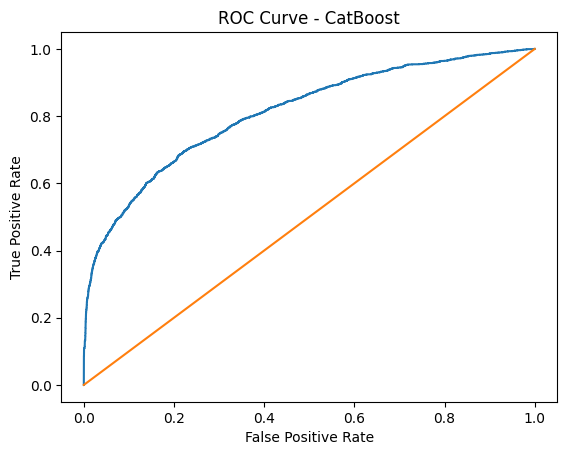

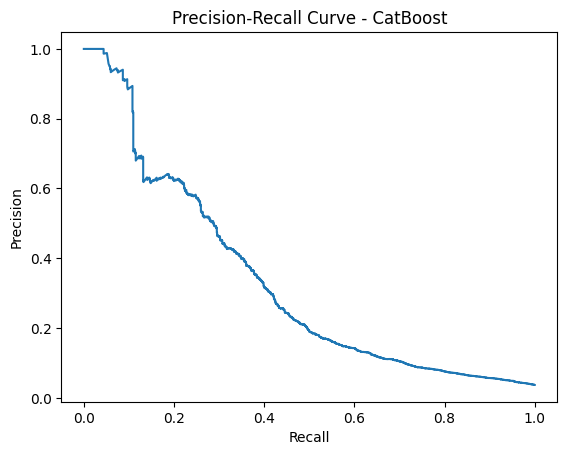

In [9]:
# Cell 6 — Prediksi probabilitas + evaluasi (ROC-AUC, PR-AUC, F1@0.5) + ROC/PR plot

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

proba_cb = catboost_vanilla.predict_proba(X_test)[:, 1]
print("Proba min/mean/max:", float(np.min(proba_cb)), float(np.mean(proba_cb)), float(np.max(proba_cb)))

roc_auc = roc_auc_score(y_test, proba_cb)
pr_auc = average_precision_score(y_test, proba_cb)

print("\nCatBoost (vanilla) ROC-AUC:", round(roc_auc, 4))
print("CatBoost (vanilla) PR-AUC :", round(pr_auc, 4))

y_pred_05 = (proba_cb >= 0.5).astype(int)
print("\nF1@0.5:", round(f1_score(y_test, y_pred_05), 4))
print("Confusion Matrix @0.5:\n", confusion_matrix(y_test, y_pred_05))
print("\nReport @0.5:\n", classification_report(y_test, y_pred_05, digits=4))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_cb)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.title("ROC Curve - CatBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# PR curve
prec, rec, _ = precision_recall_curve(y_test, proba_cb)
plt.figure()
plt.plot(rec, prec)
plt.title("Precision-Recall Curve - CatBoost")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

<h3>Cell 7 - Threshold Tuning (Best F1)</h3>
<p>
Cell ini melakukan pencarian threshold terbaik berdasarkan kurva Precision-Recall untuk memaksimalkan F1 score.
Ini bukan untuk “mengubah” metrik utama (ROC/PR-AUC tetap prioritas), tetapi untuk memberikan insight operasional:
threshold mana yang lebih tepat jika model dipakai untuk seleksi calon repeat (misalnya untuk follow-up marketing).
</p>
<p>
Hasil tuning umumnya menghasilkan threshold yang sedikit berbeda dari 0.5, dan membantu menunjukkan trade-off precision vs recall secara lebih eksplisit di laporan.
</p>

In [10]:
# Cell 7 — Threshold tuning cepat (best F1 dari PR curve)

prec, rec, thr = precision_recall_curve(y_test, proba_cb)
f1s = (2 * prec * rec) / (prec + rec + 1e-12)

best_idx = int(np.nanargmax(f1s))
best_thr = float(thr[best_idx-1]) if best_idx > 0 and (best_idx-1) < len(thr) else 0.5

y_pred_best = (proba_cb >= best_thr).astype(int)

print("Best-F1 threshold:", round(best_thr, 4))
print("F1(best):", round(f1_score(y_test, y_pred_best), 4))

Best-F1 threshold: 0.549
F1(best): 0.3752


<h3>Cell 8 - Feature Importance (CatBoost)</h3>
<p>
Cell ini mengekstrak <i>feature importance</i> dari CatBoost dan menampilkan fitur paling berpengaruh.
Bagian ini sangat berguna untuk laporan karena CatBoost dapat menunjukkan fitur mana yang paling membantu membedakan repeat vs non-repeat, misalnya:
</p>
<ul>
  <li>Demografi: <code>umur</code>, <code>gender</code>, <code>pekerjaan</code></li>
  <li>Produk: <code>kode motor</code>, <code>type series</code>, <code>tahun rakit</code></li>
  <li>Kemampuan bayar: <code>cicilan</code>, <code>dp aktual</code>, <code>otr</code></li>
  <li>Lokasi & channel: <code>kelurahan</code>, <code>kecamatan</code>, <code>wilayah</code>, <code>kode dealer</code></li>
  <li>Waktu: <code>mohon_year</code>, <code>mohon_month</code></li>
</ul>
<p>
Interpretasi utama: feature importance bersifat indikatif (korelasi), tetapi sangat membantu untuk menjelaskan faktor-faktor yang berkaitan dengan repeat order.
</p>

In [11]:
# Cell 8 — Feature importance (CatBoost)

fi = catboost_vanilla.get_feature_importance()
fi_df = pd.DataFrame({"feature": X_train.columns, "importance": fi}).sort_values("importance", ascending=False)

print("Top 30 Feature Importance (CatBoost):")
display(fi_df.head(30))

Top 30 Feature Importance (CatBoost):


,feature,importance
10,umur,10.697819
19,kode motor,7.786011
9,pekerjaan,7.614636
24,mohon_year,5.998077
21,tahun rakit,5.933234
7,gender,5.788746
0,kelurahan,5.719959
12,cicilan,5.020308
2,kode pos,3.989461
4,kode dealer,3.929161


# MODELING LGBM

<h3>Cell 1 - Load Data, Parse Tanggal, dan Filter Data Berlabel</h3>
<p>
Cell ini memuat file <code>sparc_labeled.csv</code> lalu melakukan parsing <code>tgl mohon</code> menjadi datetime. Setelah itu, kami memfilter hanya baris yang memiliki target <code>label_repeat_next</code> (drop NaN).
</p>
<p>
Alasan filtering: baris tanpa label umumnya disebabkan <code>tgl mohon</code> kosong sehingga target berbasis urutan waktu tidak dapat dibentuk. Dataset yang dihasilkan menjadi subset yang valid untuk training dan evaluasi model.
</p>

In [19]:
# Cell 1 — Load data + parse tanggal + filter berlabel
import os
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df = pd.read_csv(labeled_path)
print("Shape:", df.shape)

df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")

df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows for modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")
print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

C:\Users\timot\AppData\Local\Temp\ipykernel_26984\2813277519.py:10: DtypeWarning: Columns (3,19,23,24,25,26,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(labeled_path)


Shape: (319978, 30)
Rows for modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split (80/20)</h3>
<p>
Di cell ini, data disortir berdasarkan <code>tgl mohon</code> dan dipisah secara time-based: 80% bagian awal (periode lebih lama) untuk train dan 20% bagian akhir (periode lebih baru) untuk test.
</p>
<p>
Split time-based menjaga skenario evaluasi yang realistis (model dilatih pada histori dan diuji pada periode masa depan) sekaligus menghindari leakage.
Perbedaan repeat rate antara train dan test dapat terjadi karena right-censoring pada akhir periode data, sehingga metrik threshold-independent (ROC-AUC, PR-AUC) menjadi fokus utama.
</p>

In [20]:
# Cell 2 — Time-based train/test split (80/20)
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)
split_idx = int(len(df_model) * 0.8)

train_all = df_model.iloc[:split_idx].copy()
test_df   = df_model.iloc[split_idx:].copy()

y_test = test_df["label_repeat_next"].values

print("Train period:", train_all["tgl mohon"].min(), "->", train_all["tgl mohon"].max(), "| n:", train_all.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])
print("Train repeat rate:", round(train_all["label_repeat_next"].mean() * 100, 2), "%")
print("Test repeat rate :", round(test_df["label_repeat_next"].mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Buat Validation Set dari Bagian Akhir Train (Early Stopping)</h3>
<p>
Cell ini membuat <i>validation set</i> dari 15% bagian paling akhir pada data train (masih time-based). Struktur ini menghasilkan 3 segmen waktu:
</p>
<ul>
  <li><b>Train_inner:</b> periode lebih awal untuk training utama</li>
  <li><b>Val_inner:</b> periode lebih baru untuk early stopping/tuning</li>
  <li><b>Test:</b> periode paling akhir untuk evaluasi final</li>
</ul>
<p>
Konfigurasi seperti ini membantu LightGBM menemukan jumlah boosting rounds yang optimal tanpa overfitting dan tetap konsisten dengan alur “prediksi masa depan”.
</p>

In [ ]:
# Cell 3 — Buat validation set dari bagian paling akhir train (early stopping)
train_all = train_all.sort_values("tgl mohon").reset_index(drop=True)
val_idx = int(len(train_all) * 0.85)

train_df = train_all.iloc[:val_idx].copy()
val_df   = train_all.iloc[val_idx:].copy()

y_train = train_df["label_repeat_next"].values
y_val   = val_df["label_repeat_next"].values

print("Train_inner period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Val_inner period  :", val_df["tgl mohon"].min(),   "->", val_df["tgl mohon"].max(),   "| n:", val_df.shape[0])
print("Train_inner rate:", round(y_train.mean() * 100, 2), "%")
print("Val_inner rate  :", round(y_val.mean() * 100, 2), "%")

Train_inner period: 2019-01-02 00:00:00 -> 2024-05-22 00:00:00 | n: 151173
Val_inner period  : 2024-05-22 00:00:00 -> 2025-01-11 00:00:00 | n: 26678
Train_inner rate: 15.71 %
Val_inner rate  : 9.01 %


<h3>Cell 4 - Feature Engineering Tanggal & Drop Leakage/ID/Datetime Mentah</h3>
<p>
Cell ini menambahkan fitur turunan dari <code>tgl mohon</code> (<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, <code>mohon_quarter</code>) untuk menangkap pola musiman tanpa memasukkan datetime mentah.
</p>
<p>
Selanjutnya, kami menghapus kolom yang tidak boleh menjadi fitur:
</p>
<ul>
  <li><b>Target:</b> <code>label_repeat_next</code></li>
  <li><b>Helper labeling:</b> <code>max_tgl_mohon_customer</code> (berpotensi leakage)</li>
  <li><b>ID:</b> <code>customer id</code></li>
  <li><b>Datetime mentah:</b> <code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code></li>
</ul>
<p>
Output cell ini adalah <code>X_train</code>, <code>X_val</code>, dan <code>X_test</code> yang berisi fitur final untuk LightGBM.
</p>

In [22]:
# Cell 4 — Feature engineering tanggal + drop leakage/ID/datetime mentah
def add_time_features(_df):
    _df["mohon_year"] = _df["tgl mohon"].dt.year
    _df["mohon_month"] = _df["tgl mohon"].dt.month
    _df["mohon_dow"] = _df["tgl mohon"].dt.dayofweek
    _df["mohon_quarter"] = _df["tgl mohon"].dt.quarter
    return _df

train_df = add_time_features(train_df)
val_df   = add_time_features(val_df)
test_df  = add_time_features(test_df)

drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
    "tgl mohon", "tgl cetak", "tgl lahir"
]
drop_cols = [c for c in drop_cols if c in train_df.columns]

X_train = train_df.drop(columns=drop_cols).copy()
X_val   = val_df.drop(columns=drop_cols).copy()
X_test  = test_df.drop(columns=drop_cols).copy()

print("Dropped:", drop_cols)
print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Columns sample:", X_train.columns.tolist()[:40])

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train: (151173, 28) X_val: (26678, 28) X_test: (44463, 28)
Columns sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'kode kota-provinsi', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']


<h3>Cell 5 - Tentukan Fitur Numerik/Kategorikal & Cleaning untuk LightGBM</h3>
<p>
Cell ini memisahkan fitur numerik dan kategorikal. Kolom numerik di-cast menjadi numeric dengan <code>errors="coerce"</code>, sehingga nilai non-numerik berubah menjadi NaN dan dapat ditangani model.
</p>
<p>
Untuk fitur kategorikal, kami membersihkan nilai menjadi string dan mengganti missing/blank menjadi <code>"MISSING"</code>, lalu meng-cast kolom menjadi dtype <code>category</code>. Ini memungkinkan LightGBM memanfaatkan fitur kategorikal dengan lebih efisien dibanding OneHot besar.
</p>
<p>
Sebagai catatan, LightGBM akan menormalkan nama fitur yang mengandung whitespace menjadi underscore (warning non-fatal), sehingga nama fitur pada log dapat sedikit berbeda dari kolom asli.
</p>

In [ ]:
# Cell 5 — Tentukan num/cat + cleaning
import numpy as np
import pandas as pd

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

for c in num_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce")
    X_val[c]   = pd.to_numeric(X_val[c], errors="coerce")
    X_test[c]  = pd.to_numeric(X_test[c], errors="coerce")

def to_cat_str(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return "MISSING"
    if isinstance(v, str):
        s = v.strip()
        return "MISSING" if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train[c] = X_train[c].map(to_cat_str).astype("category")
    X_val[c]   = X_val[c].map(to_cat_str).astype("category")
    X_test[c]  = X_test[c].map(to_cat_str).astype("category")

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))
print("Cat cols sample:", cat_cols[:10])

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18
Cat cols sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'gender', 'agama', 'pekerjaan', 'warna']


<h3>Cell 6 - Training LightGBM dengan Early Stopping (Versi Stabil)</h3>
<p>
Cell ini melatih LightGBM menggunakan training API yang lebih stabil (<code>lgb.train</code>) agar proses early stopping memonitor metrik yang tepat (AUC) secara konsisten.
</p>
<p>
Kami menggunakan:
</p>
<ul>
  <li><b>scale_pos_weight</b> untuk menangani imbalance kelas pada train_inner</li>
  <li><b>Early stopping</b> untuk memilih iterasi terbaik berdasarkan performa pada val_inner</li>
  <li><b>Regularisasi</b> (feature_fraction, bagging_fraction, L1/L2) untuk mencegah overfitting</li>
</ul>
<p>
Output penting yang dicatat adalah <b>best_iteration</b> dan <b>best valid AUC</b> sebagai indikator bahwa model benar-benar belajar (bukan berhenti di iterasi sangat kecil seperti percobaan awal).
</p>

In [ ]:
import lightgbm as lgb
import numpy as np

# bikin dataset lgb
train_set = lgb.Dataset(X_train, label=y_train, categorical_feature=cat_cols, free_raw_data=False)
val_set = lgb.Dataset(X_val, label=y_val, categorical_feature=cat_cols, free_raw_data=False)

pos = float((y_train == 1).sum())
neg = float((y_train == 0).sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0
print("scale_pos_weight:", scale_pos_weight)

params = {
    "objective": "binary",
    "metric": ["auc", "binary_logloss"],  
    "learning_rate": 0.03,
    "num_leaves": 128,
    "max_depth": -1,
    "min_data_in_leaf": 30,     
    "min_sum_hessian_in_leaf": 1e-3,
    "feature_fraction": 0.85,
    "bagging_fraction": 0.85,
    "bagging_freq": 1,
    "lambda_l1": 0.5,
    "lambda_l2": 1.0,
    "scale_pos_weight": scale_pos_weight,
    "seed": RANDOM_SEED,
    "verbosity": -1
}

evals_result = {}
booster = lgb.train(
    params,
    train_set,
    num_boost_round=8000,
    valid_sets=[val_set],
    valid_names=["valid"],
    callbacks=[
        lgb.early_stopping(stopping_rounds=300, first_metric_only=True, verbose=True),
        lgb.log_evaluation(period=50),
        lgb.record_evaluation(evals_result)
    ]
)

print("Best iteration:", booster.best_iteration)
print("Best valid AUC:", evals_result["valid"]["auc"][booster.best_iteration - 1])

scale_pos_weight: 5.364642977433479
Training until validation scores don't improve for 300 rounds
[50]	valid's auc: 0.751366	valid's binary_logloss: 0.393183
[100]	valid's auc: 0.753974	valid's binary_logloss: 0.410501
[150]	valid's auc: 0.751491	valid's binary_logloss: 0.40164
[200]	valid's auc: 0.750607	valid's binary_logloss: 0.389076
[250]	valid's auc: 0.74859	valid's binary_logloss: 0.376859
[300]	valid's auc: 0.746719	valid's binary_logloss: 0.365416
[350]	valid's auc: 0.745915	valid's binary_logloss: 0.352151
Early stopping, best iteration is:
[99]	valid's auc: 0.754285	valid's binary_logloss: 0.410528
Evaluated only: auc
Best iteration: 99
Best valid AUC: 0.7542849172437605


<h3>Cell 7 - Evaluasi di Test Set (ROC-AUC, PR-AUC, F1@0.5) + Kurva</h3>
<p>
Cell ini melakukan evaluasi final pada test set menggunakan probabilitas prediksi.
Metrik utama:
</p>
<ul>
  <li><b>ROC-AUC</b> untuk menilai kualitas ranking prediksi secara global</li>
  <li><b>PR-AUC</b> untuk menilai performa pada kelas positif (repeat) yang minoritas</li>
</ul>
<p>
Selain itu, kami menghitung F1 pada threshold default 0.5 dan menampilkan confusion matrix serta classification report untuk interpretasi operasional.
Kurva ROC dan Precision-Recall juga ditampilkan untuk melihat trade-off di berbagai threshold.
</p>
<p>
Pada hasil terbaru, LightGBM menunjukkan performa yang valid dan stabil, namun masih berada di bawah CatBoost pada ROC-AUC dan PR-AUC sehingga belum menjadi model terbaik.
</p>

Proba min/mean/max: 0.039391980123996195 0.30665956116841026 0.9277978416904558

LightGBM ROC-AUC: 0.7536
LightGBM PR-AUC : 0.267

F1@0.5: 0.2843
Confusion Matrix @0.5:
 [[40323  2499]
 [  955   686]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9769    0.9416    0.9589     42822
           1     0.2154    0.4180    0.2843      1641

    accuracy                         0.9223     44463
   macro avg     0.5961    0.6798    0.6216     44463
weighted avg     0.9488    0.9223    0.9340     44463



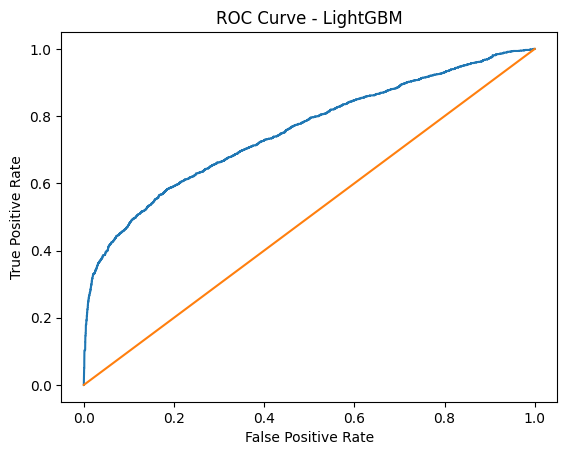

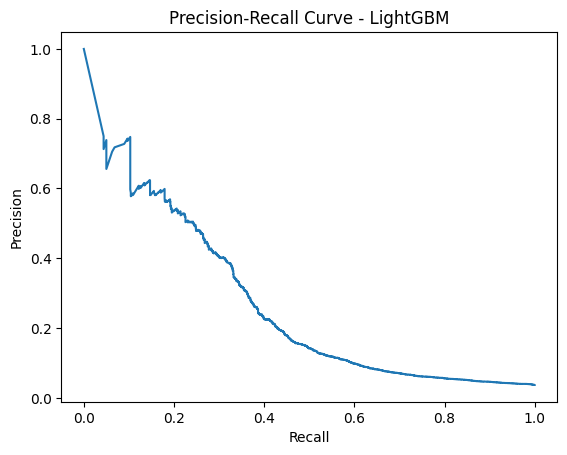

In [25]:
# Cell 7 — Evaluasi di TEST (ROC-AUC, PR-AUC, F1@0.5) + ROC/PR plot
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

proba_test = booster.predict(X_test, num_iteration=booster.best_iteration)
print("Proba min/mean/max:", float(np.min(proba_test)), float(np.mean(proba_test)), float(np.max(proba_test)))

roc_auc = roc_auc_score(y_test, proba_test)
pr_auc = average_precision_score(y_test, proba_test)

print("\nLightGBM ROC-AUC:", round(roc_auc, 4))
print("LightGBM PR-AUC :", round(pr_auc, 4))

y_pred_05 = (proba_test >= 0.5).astype(int)
print("\nF1@0.5:", round(f1_score(y_test, y_pred_05), 4))
print("Confusion Matrix @0.5:\n", confusion_matrix(y_test, y_pred_05))
print("\nReport @0.5:\n", classification_report(y_test, y_pred_05, digits=4))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_test)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.title("ROC Curve - LightGBM")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# PR curve
prec, rec, _ = precision_recall_curve(y_test, proba_test)
plt.figure()
plt.plot(rec, prec)
plt.title("Precision-Recall Curve - LightGBM")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

<h3>Cell 8 - Threshold Tuning (Best F1) untuk Interpretasi Operasional</h3>
<p>
Cell ini mencari threshold terbaik yang memaksimalkan F1 score berdasarkan kurva Precision-Recall.
Tujuannya adalah memberikan sudut pandang operasional: jika model dipakai untuk aksi (mis. follow-up), threshold default 0.5 belum tentu optimal.
</p>
<p>
Hasil tuning menghasilkan threshold yang lebih cocok untuk F1 dibanding 0.5, dan confusion matrix pada threshold tersebut membantu melihat perubahan trade-off precision vs recall.
</p>
<p>
Perlu dicatat: tuning threshold tidak mengubah kemampuan ranking model (ROC/PR-AUC), tetapi membantu memilih kebijakan keputusan yang lebih sesuai dengan tujuan bisnis/kompetisi.
</p>

In [26]:
# Cell 8 — Threshold tuning cepat (best F1)
import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score

prec, rec, thr = precision_recall_curve(y_test, proba_test)
f1s = (2 * prec * rec) / (prec + rec + 1e-12)

best_idx = int(np.nanargmax(f1s))
best_thr = float(thr[best_idx-1]) if best_idx > 0 and (best_idx-1) < len(thr) else 0.5

y_pred_best = (proba_test >= best_thr).astype(int)

print("Best-F1 threshold:", round(best_thr, 4))
print("F1(best):", round(f1_score(y_test, y_pred_best), 4))
print("Confusion Matrix @best:\n", __import__("sklearn.metrics").metrics.confusion_matrix(y_test, y_pred_best))

Best-F1 threshold: 0.61
F1(best): 0.3528
Confusion Matrix @best:
 [[41970   852]
 [ 1107   534]]


<h3>Cell 9 - Feature Importance (LightGBM)</h3>
<p>
Cell ini menampilkan feature importance dari LightGBM (berdasarkan split/gain tergantung implementasi). Tujuannya untuk interpretasi dan narasi laporan: fitur apa yang paling sering dipakai model untuk melakukan split.
</p>
<p>
Hasil importance LightGBM dapat berbeda dari CatBoost karena perbedaan cara model menangani fitur kategorikal dan strategi split. Selain itu, beberapa fitur dapat memiliki importance 0 jika tidak dipakai pada pohon hingga best_iteration yang dipilih oleh early stopping.
</p>

In [27]:
# Cell 9 — Feature importance (gain-based) + top 30
import pandas as pd

fi = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 30 Feature Importance (LightGBM):")
display(fi.head(30))

Top 30 Feature Importance (LightGBM):


,feature,importance
0,kelurahan,70
10,umur,52
2,kode pos,46
20,otr,34
4,kode dealer,28
12,cicilan,26
1,kecamatan,16
11,dp aktual,16
9,pekerjaan,14
21,tahun rakit,14


<h3>Ringkasan Perbandingan Performa Model (Baseline LR vs CatBoost vs LightGBM)</h3>

<p>
Pada tahap modeling, kami membangun <b>tiga model</b> secara bertahap untuk memprediksi target <code>label_repeat_next</code>
(0 = tidak ada transaksi berikutnya, 1 = ada transaksi berikutnya). Seluruh model dievaluasi dengan skema split berbasis waktu
untuk meniru skenario penggunaan nyata (melatih dari histori dan menguji pada periode masa depan), sehingga menghindari leakage.
</p>

<h3>Metodologi Evaluasi</h3>
<ul>
  <li>
    <b>Time-based split (80/20)</b>: 80% data dengan tanggal lebih awal untuk train, 20% tanggal lebih akhir untuk test.
    Ini membuat evaluasi realistis namun menyebabkan <i>label shift</i> (base rate di test lebih rendah karena right-censoring).
  </li>
  <li>
    <b>Metrik utama</b>: <b>ROC-AUC</b> (kualitas ranking secara global) dan <b>PR-AUC</b> (lebih relevan untuk kelas positif yang minoritas).
  </li>
  <li>
    <b>Metrik operasional</b>: F1 dan confusion matrix pada threshold (0.5 & threshold hasil tuning) untuk memahami trade-off precision–recall.
  </li>
</ul>

<h3>Tabel Perbandingan Performa (Test Set)</h3>
<table border="1" cellpadding="8" cellspacing="0">
  <thead>
    <tr>
      <th>Model</th>
      <th>Strategi Fitur</th>
      <th>Handling Imbalance</th>
      <th>ROC-AUC (Test)</th>
      <th>PR-AUC (Test)</th>
      <th>F1 @ 0.5</th>
      <th>Catatan Operasional</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>Logistic Regression (Vanilla)</b></td>
      <td>Numerik + kategori (OneHot), fitur waktu turunan</td>
      <td>Tanpa class_weight</td>
      <td><b>0.7933</b></td>
      <td><b>0.2938</b></td>
      <td>0.2701</td>
      <td>Lebih konservatif: precision tinggi, recall rendah</td>
    </tr>
    <tr>
      <td><b>Logistic Regression (Balanced)</b></td>
      <td>Numerik + kategori (OneHot), fitur waktu turunan</td>
      <td>class_weight="balanced"</td>
      <td><b>0.7941</b></td>
      <td><b>0.2863</b></td>
      <td>0.3588</td>
      <td>Lebih agresif: recall naik, precision turun</td>
    </tr>
    <tr>
      <td><b>CatBoost</b></td>
      <td>Numerik + kategori native, fitur waktu turunan</td>
      <td>scale_pos_weight</td>
      <td><b>0.8075</b></td>
      <td><b>0.3293</b></td>
      <td>0.3640</td>
      <td>Distribusi proba lebih informatif; performa terbaik secara ranking</td>
    </tr>
    <tr>
      <td><b>LightGBM</b></td>
      <td>Numerik + kategori (dtype category), fitur waktu turunan</td>
      <td>scale_pos_weight + early stopping</td>
      <td><b>0.7536</b></td>
      <td><b>0.2670</b></td>
      <td>0.2843</td>
      <td>Stabil setelah perbaikan early stopping, namun kalah dari CatBoost</td>
    </tr>
  </tbody>
</table>

<p style="margin-top:10px;">
<b>Catatan:</b> Angka-angka di atas diambil dari evaluasi test set pada eksperimen terakhir untuk masing-masing model.
Metrik yang diprioritaskan untuk kompetisi/seleksi kandidat repeat adalah <b>PR-AUC</b> karena kelas positif minoritas.
</p>

<h3>Apa yang Kami Lakukan dari Awal sampai Akhir (Modeling Journey)</h3>

<ul>
  <li>
    <b>1) Menetapkan baseline yang dapat dijelaskan (Logistic Regression)</b><br/>
    Kami memulai dari Logistic Regression untuk mendapatkan baseline yang sederhana dan interpretatif.
    Tantangan awal muncul karena data memiliki tipe campuran dan kolom tanggal mentah berpotensi ikut menjadi kategori sehingga merusak pipeline.
    Setelah revisi:
    <ul>
      <li>Datetime mentah di-drop, diganti fitur waktu turunan (<code>year/month/dow/quarter</code>).</li>
      <li>Kategori dinormalisasi menjadi string konsisten, missing diimputasi menjadi "MISSING".</li>
      <li>Two-baseline strategy: <i>vanilla vs balanced</i> untuk memperlihatkan trade-off precision–recall.</li>
    </ul>
    Hasilnya baseline sudah kuat (ROC-AUC ~0.79; PR-AUC ~0.29) dan menjadi pembanding utama.
  </li>

  <li style="margin-top:10px;">
    <b>2) Membangun model non-baseline yang kuat untuk data kategori (CatBoost)</b><br/>
    Setelah baseline stabil, kami melatih CatBoost karena mampu menangani kategori secara native tanpa OneHot besar.
    Kami menggunakan <code>scale_pos_weight</code> untuk menangani imbalance dan <i>early stopping</i> untuk memilih iterasi terbaik.
    CatBoost menghasilkan performa terbaik:
    <ul>
      <li><b>ROC-AUC tertinggi</b> dan <b>PR-AUC tertinggi</b> di test set.</li>
      <li>Probabilitas prediksi lebih tersebar (lebih berguna untuk ranking kandidat repeat).</li>
      <li>Feature importance kaya, sehingga mudah dijelaskan (demografi, produk, lokasi, waktu, dan affordability).</li>
    </ul>
  </li>

  <li style="margin-top:10px;">
    <b>3) Menguji boosting alternatif (LightGBM) sebagai pembanding “model juara”</b><br/>
    Kami mencoba LightGBM untuk mengejar performa maksimum. Pada percobaan awal, model sempat underfit karena konfigurasi terlalu ketat
    (early stopping berhenti terlalu cepat). Setelah revisi:
    <ul>
      <li>Early stopping dibuat stabil (monitoring AUC secara eksplisit).</li>
      <li>Parameter leaf/child disesuaikan agar model mampu melakukan split dan belajar pola.</li>
      <li>Kategori diproses dengan dtype <code>category</code>.</li>
    </ul>
    LightGBM akhirnya stabil, namun performa test (ROC-AUC dan PR-AUC) masih di bawah CatBoost pada dataset ini.
  </li>
</ul>

<h3>Kesimpulan untuk Juri</h3>
<p>
Berdasarkan evaluasi test set dengan split berbasis waktu dan metrik utama untuk kelas minoritas,
<b>CatBoost</b> adalah model terbaik pada eksperimen kami (<b>ROC-AUC 0.8075</b>, <b>PR-AUC 0.3293</b>).
Baseline Logistic Regression menunjukkan performa yang kuat dan interpretabilitas yang baik, sedangkan LightGBM berhasil distabilkan
namun belum melampaui CatBoost pada pengaturan saat ini.
</p>

<p>
Dengan demikian, <b>model final yang direkomendasikan</b> untuk deployment/kompetisi (sebagai “model juara”) adalah <b>CatBoost</b>,
dengan threshold dapat ditentukan sesuai tujuan (memaksimalkan precision, recall, atau F1) menggunakan kurva Precision–Recall.
</p>